# 08 — LEVIR ROI model selection and Medium diagnosis · v2

**This is the executable experiment notebook**, not the read-only preflight provided earlier. Run all cells from the top. It uses original `06` evaluation code **unchanged**, imports the live project `satchange.semantic.roi.extract_rois` and `ROISettings`, and reuses the existing V1 probability caches. **No new training** is performed.

**Validation only for selection.** Test results, if explicitly enabled, are descriptive/exploratory because earlier Research I experiments already exposed the same test set. Generated ROIs are real bounding boxes returned by the project's ROI function; dummy zero RGB tensors are passed because we only assess crop geometry, not semantic content. The WHAT model is not executed. Total downstream GPU runtime is an *illustrative cost scenario*, never a measured runtime.

**Execution:** 1) change paths/switches below; 2) Run All; 3) inspect validation selections/Medium gate; 4) optionally enable TEST (same frozen choices, no retuning); 5) export. No separate `.py` files needed. Runtime can be substantial because this executes many CPU ROI operations over 1024×1024 images. Outputs resume by configuration and image pair.

## 0. Single configuration cell — switches are real, not placeholders

In [1]:
from pathlib import Path
PROJECT_ROOT = Path('/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence')
V1_RUN = 'H1_H5_v1'
OUT_NAME = 'H08_roi_model_selection_v2'
DEVICE = 'cuda:0'

# Main ROI study executes by default; no GPU inference needed for these cached models.
RUN_ROI_VALIDATION = True
RUN_MEDIUM_SEEDS = True    # Executes extra seed validation inference (GPU; no retraining).
TRUST_OWN_SEED_CHECKPOINTS = True  # Only for the original checkpoints you trained yourself.
RUN_TEST_EVALUATION = False  # Enable only AFTER validation choices have been frozen.

# Feasible ROI strategies: the first sweep tests thresholds, refinement tests context and area.
COARSE_THRESHOLDS = (0.35, 0.55, 0.75, 0.90)
COARSE_CONTEXT_PX = 16
COARSE_MIN_COMPONENT_AREA = 16
MIN_CROP_SIZE = 128        # Matches current project ROI defaults.
REFINEMENT_CONTEXT_PX = (0, 16, 32)
REFINEMENT_MIN_COMPONENT_AREA = (1, 16, 64)
MAX_REFINEMENT_FAMILIES = 3  # Other Medium variants always included for diagnostics.

# Predeclared illustrative efficiency scenario, NOT a measurement of the WHAT model.
HYPOTHETICAL_MS_PER_CROP = 1.0
HYPOTHETICAL_MS_PER_MPIX_CROPPED = 2.0
MIN_COVERAGE_95 = 0.90  # A *selection scenario*, not a universal quality requirement.
N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 20261029

print('Project:', PROJECT_ROOT)
print('Run ROI validation:', RUN_ROI_VALIDATION, 'Medium GPU seeds:', RUN_MEDIUM_SEEDS, 'Test:', RUN_TEST_EVALUATION)

Project: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence
Run ROI validation: True Medium GPU seeds: True Test: False


## 1. Reuse original H1–H5 reader, score map and GT implementations (unchanged)

In [2]:
CORE_SOURCE = r'''"""Read-only LEVIR-CD inference and exploratory H1--H5 analysis.

Project adapter reviewed against the supplied levir_hypotheses_context.zip.
No training, downloads, writes to src/, or changes to final_models/.
"""
from __future__ import annotations

import copy
import gc
import hashlib
import itertools
import json
import math
import os
import platform
import re
import shutil
import subprocess
import sys
import time
import warnings
from collections import OrderedDict
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
from typing import Any, Mapping
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import scipy
import PIL
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from torch.nn import functional as F

IMPLEMENTATION_VERSION = "levir-H1-H5-1.0.0"
VARIANTS = ("light_full", "light_resized", "medium_full", "medium_resized",
            "heavy_full", "heavy_resized")


@dataclass
class Settings:
    project_root: str
    run_name: str = "H1_H5_v1"
    dataset_root: str | None = None
    variants: tuple[str, ...] = VARIANTS
    device: str = "cuda:0"
    include_other_seeds: bool = False
    trust_own_seed_checkpoints: bool = False
    cpu_threads: int = 4
    validation_atol: float = 0.001
    connectivity: int = 2  # 2 = 8-neighbour connectivity in a 2D mask.
    size_quantiles: tuple[float, float] = (1 / 3, 2 / 3)
    iou_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    primary_iou: float = 0.5
    coverage_thresholds: tuple[float, ...] = (0.1, 0.25, 0.5)
    boundary_tolerances_px: tuple[int, ...] = (1, 2, 4)
    primary_boundary_px: int = 2
    recall_targets: tuple[float, ...] = (0.8, 0.9)
    recall_match_tolerance: float = 0.005
    threshold_grid: tuple[float, ...] = tuple(np.linspace(0, 1, 101).tolist())
    bootstrap_repetitions: int = 1000
    bootstrap_seed: int = 20261020
    cost_source: str = "remeasure"  # or "saved_benchmark"; CSV is never used as truth.
    benchmark_warmup: int = 20
    benchmark_repetitions: int = 100
    minimum_free_gib: float = 1.0
    # Monetary values are OPTIONAL user scenarios, not measured market prices.
    gpu_price_per_hour: float | None = None
    review_price_per_alert: float | None = None
    missed_component_price: float | None = None
    scenario_pairs: int = 1000
    minimum_object_recall: float | None = None
    maximum_false_alerts_per_pair: float | None = None
    maximum_forward_ms: float | None = None
    # A CSV mapping split,sample_id,cluster_id can replace image-pair bootstrap units.
    cluster_csv: str | None = None


def _json_value(x: Any) -> Any:
    if isinstance(x, dict):
        return {str(k): _json_value(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_json_value(v) for v in x]
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, np.ndarray):
        return _json_value(x.tolist())
    if isinstance(x, np.generic):
        return _json_value(x.item())
    if isinstance(x, float) and not math.isfinite(x):
        return None
    return x


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def write_json(path: Path, obj: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    tmp.write_text(json.dumps(_json_value(obj), ensure_ascii=False, indent=2,
                              sort_keys=True, allow_nan=False), encoding="utf-8")
    tmp.replace(path)


def digest(obj: Any) -> str:
    return hashlib.sha256(json.dumps(_json_value(obj), sort_keys=True,
                                     ensure_ascii=False).encode()).hexdigest()


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(8 << 20), b""):
            h.update(block)
    return h.hexdigest()


def safe_div(a: float, b: float) -> float:
    return float(a / b) if b > 0 else float("nan")


def metric_counts(pred: np.ndarray, gt: np.ndarray) -> dict[str, int]:
    if pred.shape != gt.shape or pred.dtype != bool or gt.dtype != bool:
        raise ValueError("Expected aligned 2-D boolean masks.")
    tp = int(np.count_nonzero(pred & gt))
    fp = int(np.count_nonzero(pred & ~gt))
    pos = int(gt.sum())
    return {"tp": tp, "fp": fp, "fn": pos - tp,
            "tn": gt.size - pos - fp}


def binary_metrics(c: Mapping[str, float]) -> dict[str, float]:
    tp, fp, fn = c["tp"], c["fp"], c["fn"]
    return {"pixel_precision": safe_div(tp, tp + fp),
            "pixel_recall": safe_div(tp, tp + fn),
            "pixel_f1": safe_div(2 * tp, 2 * tp + fp + fn),
            "pixel_iou": safe_div(tp, tp + fp + fn)}


def _tag(x: float) -> str:
    return f"{round(100 * x):03d}"


def _threshold_key(t: float) -> str:
    return hashlib.sha256(np.float32(t).tobytes()).hexdigest()[:12]


def boundary(mask: np.ndarray) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      border_value=0)


def _distance_to(mask: np.ndarray) -> np.ndarray:
    if not mask.any():
        return np.full(mask.shape, np.inf, dtype=np.float32)
    return ndi.distance_transform_edt(~mask)


def inner_band(mask: np.ndarray, width: int) -> np.ndarray:
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3), bool),
                                      iterations=width, border_value=0)


def match_components(gt_labels: np.ndarray, pred_labels: np.ndarray,
                     gt_areas: np.ndarray, pred_areas: np.ndarray,
                     iou_thresholds: tuple[float, ...]) -> tuple[dict, dict]:
    """One-to-one max-cardinality matching, then max IoU among such matchings.

    The matrix includes only IDs participating in an eligible IoU edge; tiny
    unrelated predictions still count as unmatched predictions, never disappear.
    """
    ng, npred = len(gt_areas) - 1, len(pred_areas) - 1
    overlap = (gt_labels > 0) & (pred_labels > 0)
    if overlap.any():
        codes = (gt_labels[overlap].astype(np.int64) * (npred + 1)
                 + pred_labels[overlap])
        codes, intersections = np.unique(codes, return_counts=True)
        gi, pi = codes // (npred + 1), codes % (npred + 1)
        ious = intersections / (gt_areas[gi] + pred_areas[pi] - intersections)
    else:
        gi = pi = np.array([], dtype=np.int64)
        ious = np.array([], dtype=float)
    info = {
        "gt_with_multiple_overlapping_pred_components": int(
            np.count_nonzero(np.bincount(gi, minlength=ng + 1)[1:] > 1)),
        "pred_components_overlapping_multiple_gt": int(
            np.count_nonzero(np.bincount(pi, minlength=npred + 1)[1:] > 1)),
    }
    found = {}
    for threshold in iou_thresholds:
        eligible = ious >= threshold
        gids, pids = np.unique(gi[eligible]), np.unique(pi[eligible])
        pairs = {}
        if len(gids) and len(pids):
            if len(gids) * len(pids) > 10_000_000:
                raise MemoryError("Component matching matrix too large; inspect fragmented masks.")
            weight = np.zeros((len(gids), len(pids)), dtype=np.float64)
            rr, cc = np.searchsorted(gids, gi[eligible]), np.searchsorted(pids, pi[eligible])
            # Total tie-breaking contribution < 1: one extra match always wins.
            weight[rr, cc] = 1 + ious[eligible] / (min(len(gids), len(pids)) + 1)
            r, c = linear_sum_assignment(weight, maximize=True)
            keep = weight[r, c] > 0
            for ri, ci in zip(r[keep], c[keep]):
                pairs[int(gids[ri])] = (int(pids[ci]), float(
                    (weight[ri, ci] - 1) * (min(len(gids), len(pids)) + 1)))
        found[threshold] = pairs
    return found, info


def exact_threshold_counts(scores: np.ndarray, gt: np.ndarray,
                           thresholds: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Exact counts on a predeclared grid, no lossy score histogram/rounding."""
    thresholds = thresholds.astype(np.float32)
    index = np.searchsorted(thresholds, scores.ravel(), side="right")
    positive = np.bincount(index[gt.ravel()], minlength=len(thresholds) + 1)
    negative = np.bincount(index[~gt.ravel()], minlength=len(thresholds) + 1)
    return np.cumsum(positive[::-1])[::-1][1:], np.cumsum(negative[::-1])[::-1][1:]


def pair_counts(a: np.ndarray, b: np.ndarray, gt: np.ndarray) -> dict:
    common = a & b
    union = a | b
    return {
        "n_positive": int(gt.sum()), "tp_a": int((a & gt).sum()),
        "tp_b": int((b & gt).sum()), "common_tp": int((common & gt).sum()),
        "a_only_tp": int((a & ~b & gt).sum()),
        "b_only_tp": int((b & ~a & gt).sum()),
        "common_fn": int((~union & gt).sum()),
        "fp_a": int((a & ~gt).sum()), "fp_b": int((b & ~gt).sum()),
        "common_fp": int((common & ~gt).sum()),
        "tp_or": int((union & gt).sum()), "fp_or": int((union & ~gt).sum()),
        "prediction_intersection": int(common.sum()), "prediction_union": int(union.sum()),
    }


def complementarity(c: Mapping[str, float]) -> dict:
    n, best = c["n_positive"], max(c["tp_a"], c["tp_b"])
    return {
        "jaccard_tp": safe_div(c["common_tp"], c["tp_or"]),
        "jaccard_fp": safe_div(c["common_fp"], c["fp_or"]),
        "jaccard_prediction": safe_div(c["prediction_intersection"], c["prediction_union"]),
        "recall_a": safe_div(c["tp_a"], n), "recall_b": safe_div(c["tp_b"], n),
        "precision_a": safe_div(c["tp_a"], c["tp_a"] + c["fp_a"]),
        "precision_b": safe_div(c["tp_b"], c["tp_b"] + c["fp_b"]),
        "recall_or": safe_div(c["tp_or"], n),
        "precision_or": safe_div(c["tp_or"], c["tp_or"] + c["fp_or"]),
        "extra_tp_vs_best": c["tp_or"] - best,
        "delta_recall": safe_div(c["tp_or"] - best, n),
        "complementarity_gain": safe_div(c["tp_or"] - best, n - best),
        "cg_denominator": n - best,
        "recovery_of_a_fn_by_b": safe_div(c["b_only_tp"], n - c["tp_a"]),
        "recovery_of_b_fn_by_a": safe_div(c["a_only_tp"], n - c["tp_b"]),
    }


def pareto_flags(df: pd.DataFrame, maximize: list[str], minimize: list[str]) -> np.ndarray:
    values = np.column_stack([*[df[c].to_numpy(float) for c in maximize],
                              *[-df[c].to_numpy(float) for c in minimize]])
    finite = np.isfinite(values).all(axis=1)
    flags = np.zeros(len(df), dtype=bool)
    for i in np.flatnonzero(finite):
        other = values[finite]
        flags[i] = not np.any(np.all(other >= values[i], axis=1)
                              & np.any(other > values[i], axis=1))
    return flags


class Experiment:
    def __init__(self, settings: Settings):
        self.cfg = settings
        self.root = Path(settings.project_root).expanduser().resolve()
        if not (self.root / "src/satchange/models/factory.py").is_file():
            raise FileNotFoundError(f"Not the project root: {self.root}")
        if not re.fullmatch(r"[A-Za-z0-9_-]+", settings.run_name):
            raise ValueError("run_name must contain only ASCII letters, digits, '-' and '_'.")
        if not settings.variants or len(set(settings.variants)) != len(settings.variants):
            raise ValueError("Select a non-empty set of distinct variants.")
        for name in ("iou_thresholds", "coverage_thresholds", "recall_targets"):
            values = getattr(settings, name)
            if not values or any(not math.isfinite(x) or not 0 < x <= 1 for x in values):
                raise ValueError(f"{name} must contain values in (0,1].")
            if len({_tag(x) for x in values}) != len(values):
                raise ValueError(f"{name}: values need distinct integer-percentage labels.")
        if settings.cpu_threads < 1 or settings.scenario_pairs < 1:
            raise ValueError("cpu_threads and scenario_pairs must be positive.")
        if not 0 < settings.size_quantiles[0] <= settings.size_quantiles[1] < 1:
            raise ValueError("Invalid size quantiles.")
        if any(r < 1 or int(r) != r for r in settings.boundary_tolerances_px):
            raise ValueError("Boundary tolerances must be positive integer native pixels.")
        if settings.connectivity not in (1, 2):
            raise ValueError("connectivity must be 1 (4 neighbours) or 2 (8 neighbours).")
        if settings.primary_iou not in settings.iou_thresholds:
            raise ValueError("primary_iou must be in iou_thresholds.")
        if settings.primary_boundary_px not in settings.boundary_tolerances_px:
            raise ValueError("primary_boundary_px must be in boundary_tolerances_px.")
        if settings.cost_source not in ("remeasure", "saved_benchmark"):
            raise ValueError("cost_source must be remeasure or saved_benchmark.")
        if settings.include_other_seeds and not settings.trust_own_seed_checkpoints:
            raise ValueError("Full seed checkpoints require explicit trust_own_seed_checkpoints=True.")
        if settings.bootstrap_repetitions < 100:
            warnings.warn("Fewer than 100 bootstrap replicates: debugging only, not a stable CI.")
        if settings.benchmark_repetitions < 1 or settings.benchmark_warmup < 0:
            raise ValueError("Invalid benchmark repetition counts.")
        for name in ("gpu_price_per_hour", "review_price_per_alert", "missed_component_price"):
            v = getattr(settings, name)
            if v is not None and (not math.isfinite(v) or v < 0):
                raise ValueError(f"{name} must be nonnegative or None.")
        self.device = torch.device(settings.device)
        if self.device.type == "cuda":
            if not torch.cuda.is_available():
                raise RuntimeError("CUDA unavailable. Choose the project's GPU kernel or set device='cpu'.")
            if self.device.index is None:
                self.device = torch.device("cuda:0")
            if self.device.index >= torch.cuda.device_count():
                raise ValueError("Requested CUDA device is not visible.")
        torch.set_num_threads(settings.cpu_threads)
        src = str(self.root / "src")
        if src not in sys.path:
            sys.path.insert(0, src)
        import satchange
        loaded = Path(satchange.__file__).resolve()
        if not loaded.is_relative_to(self.root / "src"):
            raise RuntimeError(f"Wrong satchange imported from {loaded}. Restart kernel in Research I.")
        from satchange.data.levir_cd import LEVIRCDDataset
        from satchange.models import create_change_model
        from satchange.final_benchmark import _runtime, _load_checkpoint, _instantiate
        self.Dataset = LEVIRCDDataset
        self.create_model = create_change_model
        self.runtime = _runtime  # Reuse the project's FP32/TF32 runtime controls.
        self.project_load_checkpoint = _load_checkpoint
        self.project_instantiate = _instantiate
        self.dataset_root = Path(settings.dataset_root or self.root / "data/LEVIR-CD").expanduser().resolve()
        self.datasets = {s: self.Dataset(self.dataset_root, s, None, transform=None)
                         for s in ("val", "test")}
        self.out = self.root / "artifacts/hypothesis_tests" / settings.run_name
        self.reports = self.out / "reports"
        self.reports.mkdir(parents=True, exist_ok=True)
        self.cache = self.out / "cache"
        self.cache.mkdir(exist_ok=True)
        self.gt_structure = ndi.generate_binary_structure(2, settings.connectivity)
        self.specs = self._specs()
        self.spec_by_id = {s["run_id"]: s for s in self.specs}
        self.primary = [s for s in self.specs if s["primary"]]
        self.source_manifest = {
            str(p.relative_to(self.root)): sha256_file(p)
            for p in sorted((self.root / "src/satchange").rglob("*.py"))}
        self.cluster_map = self._clusters()
        print("Hashing validation/test inputs for cache integrity (no test metrics)...", flush=True)
        self.data_manifest = self._data_manifest()
        self.protocol = {
            "implementation": IMPLEMENTATION_VERSION,
            "implementation_sha256": globals().get("IMPLEMENTATION_SHA256") or (sha256_file(Path(__file__)) if "__file__" in globals() else IMPLEMENTATION_VERSION),
            "settings": asdict(settings), "sources": self.source_manifest,
            "specs": self.specs, "data_manifest": self.data_manifest,
            "cluster_map": self.cluster_map,
            "environment": {"python": platform.python_version(), "torch": str(torch.__version__),
                            "numpy": np.__version__, "pandas": pd.__version__,
                            "scipy": scipy.__version__, "Pillow": PIL.__version__,
                            "cudnn": torch.backends.cudnn.version(),
                            "deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
                            "cuda": torch.version.cuda, "device": str(self.device),
                            "gpu": torch.cuda.get_device_name(self.device)
                            if self.device.type == "cuda" else None},
            "common_grid": "native GT; float32 sigmoid scores; bilinear upsample before >= threshold; align_corners=False",
            "scope": "post-hoc exploratory inference; no new architecture-causal claim",
        }
        self.signature = digest(self.protocol)
        manifest_path = self.out / "run_manifest.json"
        if manifest_path.exists() and read_json(manifest_path)["signature"] != self.signature:
            raise RuntimeError("Run inputs/code/settings changed. Choose a NEW run_name; old caches are preserved.")
        if not manifest_path.exists():
            write_json(manifest_path, {"signature": self.signature, "protocol": self.protocol,
                                      "created_utc": datetime.now(timezone.utc).isoformat()})
        self._audit()
        self.plan = read_json(self.out / "protocol_frozen.json") if (self.out / "protocol_frozen.json").exists() else None
        print(f"Output: {self.out}\nModels/checkpoints: {len(self.specs)}; primary pipelines: {len(self.primary)}")
        self._storage_check()

    def _specs(self) -> list[dict]:
        result = []
        for variant in self.cfg.variants:
            if variant not in VARIANTS:
                raise ValueError(f"Unknown variant: {variant}")
            folder = self.root / "artifacts/final_models" / variant
            meta = read_json(folder / "metadata.json")
            val = read_json(folder / "validation_results.json")
            if not {"model_name", "model_parameters", "image_size", "deployment_seed", "deployment_threshold"} <= meta.keys():
                raise ValueError(f"Incomplete metadata: {folder}")
            dep = int(meta["deployment_seed"])
            rows = {int(r["seed"]): r for r in val["results"]}
            available = sorted(int(p.name.split("_")[1]) for p in folder.glob("seed_*_best.pt"))
            seeds = [dep] + ([s for s in available if s != dep] if self.cfg.include_other_seeds else [])
            for seed in seeds:
                primary = seed == dep
                file = folder / ("deployment_weights.pt" if primary else f"seed_{seed}_best.pt")
                if not file.is_file():
                    raise FileNotFoundError(file)
                if seed not in rows:
                    raise ValueError(f"No validation record for {variant} seed {seed}")
                row = rows[seed]
                threshold = float(meta["deployment_threshold"] if primary else row["validation_threshold"])
                if not 0 < threshold < 1:
                    raise ValueError("Saved thresholds must be in (0,1).")
                if abs(threshold - float(row["validation_threshold"])) > 1e-9:
                    raise ValueError(f"Threshold conflict in {variant}/{seed}")
                image_size = meta["image_size"]  # Respect Medium Full's stored 1024, not an invented None.
                if variant.endswith("resized") and image_size != 256:
                    raise ValueError(f"Unexpected resized geometry for {variant}")
                if variant.endswith("full") and image_size not in (None, 1024):
                    raise ValueError(f"Unexpected full geometry for {variant}")
                result.append({"variant": variant, "run_id": f"{variant}__s{seed}",
                    "family": variant.split("_")[0], "resolution": variant.split("_")[1],
                    "seed": seed, "primary": primary, "image_size": image_size,
                    "model_name": meta["model_name"], "model_parameters": meta["model_parameters"],
                    "saved_threshold": threshold, "weight_file": str(file),
                    "weight_sha256": sha256_file(file),
                    "metadata_sha256": sha256_file(folder / "metadata.json"),
                    "validation_sha256": sha256_file(folder / "validation_results.json"),
                    "benchmark_sha256": sha256_file(folder / "benchmark.json"),
                    "expected_validation_f1": row["validation_f1"],
                    "expected_validation_iou": row["validation_iou"],
                    "expected_validation_pairs": val.get("number_of_pairs"),
                    "available_seed_files": available})
        return result

    def _clusters(self) -> dict:
        if self.cfg.cluster_csv is None:
            return {}
        path = Path(self.cfg.cluster_csv).expanduser()
        df = pd.read_csv(path, dtype=str)
        if not {"split", "sample_id", "cluster_id"} <= set(df):
            raise ValueError("cluster_csv needs split,sample_id,cluster_id columns.")
        if df.duplicated(["split", "sample_id"]).any() or df.isna().any().any():
            raise ValueError("Duplicate or missing cluster identifiers.")
        mapping = {f"{r.split}/{r.sample_id}": r.cluster_id for r in df.itertuples()}
        for split, ds in self.datasets.items():
            for sid in ds.sample_ids:
                if f"{split}/{sid}" not in mapping:
                    raise ValueError(f"Missing cluster for {split}/{sid}")
        return mapping

    def _data_manifest(self) -> dict:
        result = {}
        pair_hashes = {}
        for split, ds in self.datasets.items():
            result[split] = []
            pair_hashes[split] = set()
            for sid in ds.sample_ids:
                row = {"sample_id": sid}
                hashes = []
                for key, files in (("A", ds.before_files), ("B", ds.after_files), ("label", ds.label_files)):
                    p = files[sid]
                    h = sha256_file(p)
                    row[key] = {"file": str(p), "bytes": p.stat().st_size, "sha256": h}
                    hashes.append(h)
                pair_hashes[split].add(tuple(hashes[:2]))
                result[split].append(row)
        if pair_hashes["val"] & pair_hashes["test"]:
            raise ValueError("Identical RGB pairs detected in validation and test. Resolve split leakage first.")
        return result

    def _audit(self) -> None:
        table = pd.DataFrame([{k: s[k] for k in ("run_id", "variant", "seed", "primary", "image_size",
            "model_name", "saved_threshold", "available_seed_files")} | {"parameters": json.dumps(s["model_parameters"])}
                                for s in self.specs])
        table.to_csv(self.reports / "inventory.csv", index=False)
        issues = []
        for family in ("light", "medium", "heavy"):
            group = [s for s in self.primary if s["family"] == family]
            if len(group) == 2 and group[0]["model_parameters"] != group[1]["model_parameters"]:
                issues.append(f"{family}: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.")
        for s in self.primary:
            if len(s["available_seed_files"]) < 2:
                issues.append(f"{s['variant']}: only one seed file; no estimate of training-seed variance.")
        csv = self.root / "artifacts/final_models/final_models_metrics.csv"
        if csv.exists():
            original = pd.read_csv(csv)
            original.to_csv(self.reports / "historical_metrics_csv_NOT_USED.csv", index=False)
            if "f1_key" in original and not original["f1_key"].eq("test_f1").all():
                issues.append("final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.")
        old_cost = self.root / "artifacts/final_models/final_models_gpu_cost.csv"
        costs = []
        if old_cost.exists():
            c = pd.read_csv(old_cost)
            for s in self.primary:
                b = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
                row = c.loc[c["model"] == s["variant"]]
                costs.append({"variant": s["variant"], "benchmark_json_ms": b.get("latency_ms_per_pair"),
                    "cost_csv_ms": float(row.iloc[0]["latency_ms"]) if len(row) else np.nan})
            pd.DataFrame(costs).to_csv(self.reports / "historical_cost_discrepancies.csv", index=False)
            issues.append("Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.")
        issues += ["Connected GT components are change regions, NOT guaranteed building-instance labels.",
                   "Earlier test scores were already inspected: these analyses are exploratory/post-hoc.",
                   "A deployment checkpoint is not an independent replicate of its source seed.",
                   "No automatic hypothesis-proved labels are produced."]
        write_json(self.reports / "audit_notes.json", issues)
        print("\n".join("NOTE: " + x for x in issues), flush=True)

    def _storage_check(self) -> None:
        # Conservative native-cache estimate assuming 1024x1024 native images.
        n = sum(len(ds) for ds in self.datasets.values())
        bytes_needed = sum(n * 4 * ((s["image_size"] or 1024) ** 2) for s in self.specs)
        free = shutil.disk_usage(self.out).free
        print(f"Score cache upper estimate: {bytes_needed / 2**30:.2f} GiB; free disk: {free / 2**30:.1f} GiB.")
        if free < bytes_needed + self.cfg.minimum_free_gib * 2**30:
            warnings.warn("Free disk may be insufficient for all caches. Existing cache files are not deducted from this conservative estimate.")

    def _load_model(self, s: dict) -> torch.nn.Module:
        path = Path(s["weight_file"])
        if sha256_file(path) != s["weight_sha256"]:
            raise RuntimeError(f"Weights changed during run: {path}")
        if s["primary"]:
            state = torch.load(path, map_location="cpu", weights_only=True)
            if not isinstance(state, Mapping) or not state or not all(
                isinstance(v, torch.Tensor) for v in state.values()):
                raise TypeError("deployment_weights.pt must be a plain tensor state_dict.")
        else:
            # Only explicitly trusted, locally produced full checkpoints.
            state, cp = self.project_load_checkpoint(path)
            config = cp.get("parameters", cp.get("config", {})) or {}
            actual_seed = cp.get("seed", config.get("seed"))
            if actual_seed is not None and int(actual_seed) != s["seed"]:
                raise ValueError("Checkpoint seed mismatch.")
            actual_model = cp.get("model_parameters", config.get("model_parameters"))
            if actual_model is not None:
                # Compare recorded values, not invented constructor defaults.
                for key, val in actual_model.items():
                    if key in s["model_parameters"] and _json_value(val) != _json_value(s["model_parameters"][key]):
                        raise ValueError(f"Architecture conflict: {s['run_id']} {key}")
        # Reviewed project helper: no external pretraining download; strict=True.
        return self.project_instantiate(s["model_name"], s["model_parameters"], state)

    def _release(self) -> None:
        gc.collect()
        if self.device.type == "cuda":
            with torch.cuda.device(self.device):
                torch.cuda.empty_cache()

    def _sync(self) -> None:
        if self.device.type == "cuda":
            torch.cuda.synchronize(self.device)

    def _native_path(self, s: dict, split: str, index: int) -> Path:
        return self.cache / s["run_id"] / split / f"{index:05d}.npy"

    def _native_score(self, s: dict, split: str, index: int) -> np.ndarray:
        p = self._native_path(s, split, index)
        if not p.is_file():
            raise FileNotFoundError(f"Run inference for {s['run_id']} {split}: {p}")
        a = np.load(p, allow_pickle=False)
        if a.dtype != np.float32 or a.ndim != 2 or not np.isfinite(a).all():
            raise ValueError(f"Invalid cached score file: {p}")
        return a

    def score(self, s: dict, split: str, index: int) -> np.ndarray:
        a = self._native_score(s, split, index)
        shape = self.gt(split, index)["mask"].shape
        if a.shape != shape:
            with torch.inference_mode():
                a = F.interpolate(torch.from_numpy(a)[None, None], size=shape,
                                  mode="bilinear", align_corners=False)[0, 0].numpy()
        return a

    @lru_cache(maxsize=2)
    def gt(self, split: str, index: int) -> dict:
        ds = self.datasets[split]
        sid = ds.sample_ids[index]
        with Image.open(ds.label_files[sid]) as im:
            mask = np.array(im.convert("L"), dtype=np.uint8) > 0
        labels, ng = ndi.label(mask, structure=self.gt_structure)
        areas = np.bincount(labels.ravel(), minlength=ng + 1)
        objects = ndi.find_objects(labels)
        border_ids = set(np.unique(np.concatenate((labels[0], labels[-1], labels[:, 0], labels[:, -1]))))
        b = boundary(mask)
        return {"sample_id": sid, "mask": mask, "labels": labels, "areas": areas,
                "n_gt": ng, "slices": objects, "border_ids": border_ids,
                "boundary": b, "distance": _distance_to(b),
                "inner_band": inner_band(mask, self.cfg.primary_boundary_px)}

    def run_variant(self, variant: str, split: str = "val") -> None:
        if split not in ("val", "test"):
            raise ValueError(split)
        if split == "test" and self.plan is None:
            raise RuntimeError("Freeze the validation protocol before test inference.")
        matching = [s for s in self.specs if s["variant"] == variant]
        if not matching:
            raise ValueError(f"Variant not enabled: {variant}")
        for s in matching:
            self._run_checkpoint(s, split)

    def _run_checkpoint(self, s: dict, split: str) -> None:
        ds = self.Dataset(self.dataset_root, split, s["image_size"], transform=None)
        if ds.sample_ids != self.datasets[split].sample_ids:
            raise ValueError("Sample IDs/order differ between model and native evaluation.")
        folder = self.cache / s["run_id"] / split
        folder.mkdir(parents=True, exist_ok=True)
        completed = folder / "complete.json"
        if completed.exists():
            info = read_json(completed)
            if info["signature"] != self.signature:
                raise RuntimeError("Stale score cache.")
            if all(self._native_path(s, split, i).is_file() for i in range(len(ds))):
                print(f"CACHE {s['run_id']} {split}: {len(ds)} pairs")
                return
        model = None
        count = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}
        parameters = None
        t0 = time.perf_counter()
        try:
            with self.runtime(self.device), torch.inference_mode():
                for i in range(len(ds)):
                    p = self._native_path(s, split, i)
                    sample = ds[i]
                    if p.exists():
                        probabilities = self._native_score(s, split, i)
                    else:
                        if shutil.disk_usage(self.out).free < self.cfg.minimum_free_gib * 2**30:
                            raise OSError("Disk reserve reached. Completed scores preserved; free space and resume.")
                        if model is None:
                            model = self._load_model(s).to(self.device)
                            parameters = sum(p.numel() for p in model.parameters())
                        a = sample["before"][None].to(self.device, dtype=torch.float32)
                        b = sample["after"][None].to(self.device, dtype=torch.float32)
                        logits = model(a, b)
                        if not isinstance(logits, torch.Tensor) or tuple(logits.shape) != (1, 1, *a.shape[-2:]):
                            raise ValueError(f"Unexpected output shape for {s['run_id']}")
                        probabilities = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
                        if not np.isfinite(probabilities).all():
                            raise ValueError("Non-finite predictions.")
                        tmp = p.with_suffix(".tmp")
                        with tmp.open("wb") as f:
                            np.save(f, probabilities, allow_pickle=False)
                        tmp.replace(p)
                        del a, b, logits
                    gt = sample["mask"][0].numpy() >= 0.5
                    if probabilities.shape != gt.shape:
                        raise ValueError("Native output and processed target do not align.")
                    for k, v in metric_counts(probabilities >= np.float32(s["saved_threshold"]), gt).items():
                        count[k] += v
                    if i == 0 or (i + 1) % 16 == 0 or i + 1 == len(ds):
                        print(f"{s['run_id']:25s} {split}: {i+1}/{len(ds)}", flush=True)
            result = {"signature": self.signature, "run_id": s["run_id"], "split": split,
                      "n_pairs": len(ds), "saved_threshold": s["saved_threshold"],
                      "native_counts": count, "native_metrics": binary_metrics(count),
                      "parameters": parameters, "elapsed_with_io_and_cache_seconds": time.perf_counter() - t0}
            write_json(completed, result)
        finally:
            del model
            self._release()

    def _reproduction(self) -> pd.DataFrame:
        rows = []
        for s in self.specs:
            p = self.cache / s["run_id"] / "val/complete.json"
            if not p.exists():
                raise RuntimeError(f"Validation inference incomplete: {s['run_id']}")
            r = read_json(p)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale validation cache.")
            n_ok = s["expected_validation_pairs"] in (None, r["n_pairs"])
            df1 = r["native_metrics"]["pixel_f1"] - s["expected_validation_f1"]
            diou = r["native_metrics"]["pixel_iou"] - s["expected_validation_iou"]
            rows.append({"run_id": s["run_id"], "pairs": r["n_pairs"],
                "native_f1": r["native_metrics"]["pixel_f1"], "saved_f1": s["expected_validation_f1"],
                "native_iou": r["native_metrics"]["pixel_iou"], "saved_iou": s["expected_validation_iou"],
                "delta_f1": df1, "delta_iou": diou,
                "passed": n_ok and abs(df1) <= self.cfg.validation_atol and abs(diou) <= self.cfg.validation_atol})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / "validation_reproduction.csv", index=False)
        if not df["passed"].all():
            raise RuntimeError("Validation reproduction failed. Inspect validation_reproduction.csv. Do not tune on test or bypass this check blindly.")
        return df

    def _curve(self, s: dict) -> pd.DataFrame:
        grid = np.unique(np.array([*self.cfg.threshold_grid, s["saved_threshold"]], dtype=np.float32))
        if np.any(np.diff(grid) <= 0) or grid[0] < 0 or grid[-1] > 1:
            raise ValueError("Thresholds must be unique and in [0,1].")
        tp, fp = np.zeros(len(grid), np.int64), np.zeros(len(grid), np.int64)
        pos = neg = 0
        for i in range(len(self.datasets["val"])):
            g = self.gt("val", i)["mask"]
            p, n = exact_threshold_counts(self.score(s, "val", i), g, grid)
            tp += p; fp += n
            pos += int(g.sum()); neg += int((~g).sum())
        records = []
        for t, p, f in zip(grid, tp, fp):
            c = {"tp": int(p), "fp": int(f), "fn": pos-int(p), "tn": neg-int(f)}
            records.append({"run_id": s["run_id"], "threshold": float(t), **c, **binary_metrics(c)})
        return pd.DataFrame(records)

    @staticmethod
    def _at_recall(curve: pd.DataFrame, target: float) -> dict:
        feasible = curve.loc[curve["pixel_recall"] >= target - 1e-12].copy()
        if feasible.empty:
            return {"attainable": False, "target_recall": target, "threshold": None}
        # Minimal recall overshoot, then best precision, then highest threshold.
        row = feasible.sort_values(["pixel_recall", "pixel_precision", "threshold"],
                                   ascending=[True, False, False], na_position="last").iloc[0]
        return {"attainable": True, "target_recall": target, "threshold": float(row["threshold"]),
                "validation_recall": float(row["pixel_recall"]),
                "validation_precision": float(row["pixel_precision"])}

    def _make_operations(self, curves: dict[str, pd.DataFrame]) -> dict:
        operations = {}
        for s in self.specs:
            curve = curves[s["run_id"]]
            best = curve.sort_values(["pixel_f1", "pixel_precision", "threshold"],
                                     ascending=[False, False, False], na_position="last").iloc[0]
            ops = {"saved": {"threshold": s["saved_threshold"], "attainable": True},
                   "val_f1": {"threshold": float(best["threshold"]), "attainable": True,
                              "validation_f1": float(best["pixel_f1"])}}
            for r in self.cfg.recall_targets:
                ops[f"recall_{_tag(r)}"] = self._at_recall(curve, r)
            operations[s["run_id"]] = ops
        return operations

    def _size_cutoffs(self) -> list[float]:
        areas = np.concatenate([self.gt("val", i)["areas"][1:]
                                for i in range(len(self.datasets["val"]))])
        if not len(areas):
            raise ValueError("No validation GT components.")
        cuts = np.quantile(areas, self.cfg.size_quantiles).tolist()
        if cuts[0] == cuts[1]:
            warnings.warn("Tied size cutoffs: some bins can be empty; these metrics remain undefined.")
        return cuts

    def _size(self, area: int, cuts: list[float]) -> str:
        return "small" if area <= cuts[0] else "medium" if area <= cuts[1] else "large"

    def _evaluate_mask(self, pred: np.ndarray, gt: dict, cuts: list[float],
                       geometry: bool = True) -> tuple[dict, list[dict]]:
        g, gl = gt["mask"], gt["labels"]
        pl, npred = ndi.label(pred, structure=self.gt_structure)
        pa = np.bincount(pl.ravel(), minlength=npred + 1)
        matched, overlap_info = match_components(gl, pl, gt["areas"], pa, self.cfg.iou_thresholds)
        inside = np.bincount(gl[pred].ravel(), minlength=gt["n_gt"] + 1)
        band_pixels = np.bincount(gl[gt["inner_band"]].ravel(), minlength=gt["n_gt"] + 1)
        row = {"sample_id": gt["sample_id"], **metric_counts(pred, g),
               "n_gt": gt["n_gt"], "n_pred": npred, **overlap_info}
        for t, pairs in matched.items():
            tag = _tag(t)
            row.update({f"obj_tp_{tag}": len(pairs), f"obj_fp_{tag}": npred-len(pairs),
                        f"obj_fn_{tag}": gt["n_gt"]-len(pairs)})
        for name in ("small", "medium", "large"):
            row.update({f"{name}_gt": 0, f"{name}_tp_pixels": 0,
                        f"{name}_positive_pixels": 0, f"{name}_obj_tp": 0,
                        f"{name}_nonborder_gt": 0, f"{name}_nonborder_obj_tp": 0})
        row["completely_missed_gt"] = int(np.count_nonzero(inside[1:] == 0))
        for t in self.cfg.coverage_thresholds:
            coverage = inside[1:] / gt["areas"][1:]
            row[f"coverage_hits_{_tag(t)}"] = int(np.count_nonzero(coverage >= t))
        if geometry:
            pb = boundary(pred)
            pdistance = _distance_to(pb)
            row.update(boundary_pred_count=int(pb.sum()), boundary_gt_count=int(gt["boundary"].sum()))
            for r in self.cfg.boundary_tolerances_px:
                row[f"boundary_matched_pred_{r}"] = int(np.count_nonzero(pb & (gt["distance"] <= r)))
                row[f"boundary_matched_gt_{r}"] = int(np.count_nonzero(gt["boundary"] & (pdistance <= r)))
            band = inner_band(pred, self.cfg.primary_boundary_px)
            row["boundary_iou_intersection"] = int((band & gt["inner_band"]).sum())
            row["boundary_iou_union"] = int((band | gt["inner_band"]).sum())
            near = gt["distance"] <= self.cfg.primary_boundary_px
            row.update({"boundary_error_count": int(((pred != g) & near).sum()),
                        "boundary_band_pixels": int(near.sum()),
                        "interior_fn": int((~pred & g & ~near).sum()),
                        "interior_pixels": int((g & ~near).sum()),
                        "far_background_fp": int((pred & ~g & ~near).sum()),
                        "far_background_pixels": int((~g & ~near).sum())})
            pred_slices = ndi.find_objects(pl)
        components = []
        primary_pairs = matched[self.cfg.primary_iou]
        for gid in range(1, gt["n_gt"] + 1):
            area = int(gt["areas"][gid])
            size = self._size(area, cuts)
            hit = gid in primary_pairs
            border = gid in gt["border_ids"]
            row[f"{size}_gt"] += 1
            row[f"{size}_obj_tp"] += int(hit)
            row[f"{size}_positive_pixels"] += area
            row[f"{size}_tp_pixels"] += int(inside[gid])
            if not border:
                row[f"{size}_nonborder_gt"] += 1
                row[f"{size}_nonborder_obj_tp"] += int(hit)
            c = {"sample_id": gt["sample_id"], "gt_id": gid,
                 "component_key": f"{gt['sample_id']}::{gid}", "area_px": area,
                 "size_bin": size, "border_truncated": border,
                 "covered_pixels": int(inside[gid]), "coverage": float(inside[gid] / area),
                 "completely_missed": inside[gid] == 0,
                 "has_interior_at_primary_width": bool(area > band_pixels[gid]),
                 "matched_boundary_iou": np.nan, "matched_mask_iou": np.nan}
            for t, pairs in matched.items():
                c[f"detected_iou_{_tag(t)}"] = gid in pairs
                c[f"matched_iou_{_tag(t)}"] = pairs[gid][1] if gid in pairs else np.nan
            if hit:
                pid, iou = primary_pairs[gid]
                c["matched_mask_iou"] = iou
                if geometry:
                    gs, ps = gt["slices"][gid-1], pred_slices[pid-1]
                    region = tuple(slice(min(a.start, b.start), max(a.stop, b.stop))
                                   for a, b in zip(gs, ps))
                    gb = inner_band(gl[region] == gid, self.cfg.primary_boundary_px)
                    pb = inner_band(pl[region] == pid, self.cfg.primary_boundary_px)
                    c["matched_boundary_iou"] = safe_div(int((gb & pb).sum()), int((gb | pb).sum()))
            components.append(c)
        return row, components

    def _counts_to_metrics(self, sums: Mapping[str, float], n_pairs: int) -> dict:
        m = binary_metrics(sums)
        m.update({"gt_components": sums["n_gt"], "predicted_components": sums["n_pred"],
                  "pairs": n_pairs, "alerts_per_pair": safe_div(sums["n_pred"], n_pairs),
                  "completely_missed_fraction": safe_div(sums["completely_missed_gt"], sums["n_gt"])})
        for t in self.cfg.iou_thresholds:
            tag = _tag(t)
            tp, fp, fn = (sums[f"obj_{k}_{tag}"] for k in ("tp", "fp", "fn"))
            m.update({f"object_precision_{tag}": safe_div(tp, tp+fp),
                      f"object_recall_{tag}": safe_div(tp, tp+fn),
                      f"object_f1_{tag}": safe_div(2*tp, 2*tp+fp+fn),
                      f"false_alerts_per_pair_{tag}": safe_div(fp, n_pairs),
                      f"detected_components_{tag}": tp, f"missed_components_{tag}": fn})
        for t in self.cfg.coverage_thresholds:
            m[f"gt_coverage_recall_{_tag(t)}"] = safe_div(sums[f"coverage_hits_{_tag(t)}"], sums["n_gt"])
        for name in ("small", "medium", "large"):
            m[f"{name}_object_recall"] = safe_div(sums[f"{name}_obj_tp"], sums[f"{name}_gt"])
            m[f"{name}_pixel_recall"] = safe_div(sums[f"{name}_tp_pixels"], sums[f"{name}_positive_pixels"])
            m[f"{name}_nonborder_object_recall"] = safe_div(sums[f"{name}_nonborder_obj_tp"], sums[f"{name}_nonborder_gt"])
        if "boundary_pred_count" in sums:
            for r in self.cfg.boundary_tolerances_px:
                p = safe_div(sums[f"boundary_matched_pred_{r}"], sums["boundary_pred_count"])
                recall = safe_div(sums[f"boundary_matched_gt_{r}"], sums["boundary_gt_count"])
                if sums["boundary_pred_count"] == 0 and sums["boundary_gt_count"] > 0:
                    bf = 0.0
                elif sums["boundary_gt_count"] == 0 and sums["boundary_pred_count"] > 0:
                    bf = 0.0
                elif not np.isfinite(p+recall):
                    bf = np.nan
                else:
                    bf = 0.0 if p+recall == 0 else 2*p*recall/(p+recall)
                m[f"boundary_precision_{r}px"] = p
                m[f"boundary_recall_{r}px"] = recall
                m[f"boundary_f1_{r}px"] = bf
            m["boundary_iou"] = safe_div(sums["boundary_iou_intersection"], sums["boundary_iou_union"])
            m["boundary_error_rate"] = safe_div(sums["boundary_error_count"], sums["boundary_band_pixels"])
            m["interior_fn_rate"] = safe_div(sums["interior_fn"], sums["interior_pixels"])
            m["far_background_fp_rate"] = safe_div(sums["far_background_fp"], sums["far_background_pixels"])
        return m

    def _evaluate_operation(self, s: dict, split: str, threshold: float, cuts: list) -> tuple[pd.DataFrame, pd.DataFrame]:
        folder = self.cache / "analysis" / split / s["run_id"] / _threshold_key(threshold)
        marker = folder / "complete.json"
        if marker.exists():
            info = read_json(marker)
            if info["signature"] != self.signature or info["cutoffs"] != cuts:
                raise RuntimeError("Stale metric cache.")
            images = pd.read_csv(folder / "images.csv", dtype={"sample_id": str})
            objects = pd.read_csv(folder / "components.csv", dtype={"sample_id": str})
            return images, objects
        folder.mkdir(parents=True, exist_ok=True)
        image_rows, object_rows = [], []
        for i in range(len(self.datasets[split])):
            scores = self.score(s, split, i)
            row, components = self._evaluate_mask(scores >= np.float32(threshold), self.gt(split, i), cuts)
            image_rows.append(row); object_rows.extend(components)
        images = pd.DataFrame(image_rows)
        objects = pd.DataFrame(object_rows)
        if objects.empty:
            objects = pd.DataFrame(columns=["sample_id", "gt_id", "component_key", "area_px", "size_bin"])
        images.to_csv(folder / "images.csv", index=False)
        objects.to_csv(folder / "components.csv", index=False)
        write_json(marker, {"signature": self.signature, "cutoffs": cuts, "threshold": threshold})
        return images, objects

    def evaluate_split(self, split: str, plan: dict) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
        summaries, all_images, all_objects = [], [], []
        for s in self.specs:
            for policy, op in plan["operations"][s["run_id"]].items():
                if not op["attainable"]:
                    continue
                print(f"METRICS {split} {s['run_id']} {policy}", flush=True)
                images, objects = self._evaluate_operation(s, split, op["threshold"], plan["size_cutoffs_px"])
                identity = {"run_id": s["run_id"], "variant": s["variant"], "seed": s["seed"],
                            "primary": s["primary"], "policy": policy, "split": split,
                            "threshold": op["threshold"]}
                sums = images.select_dtypes(include=[np.number]).sum().to_dict()
                summaries.append({**identity, **self._counts_to_metrics(sums, len(images)),
                                  "target_pixel_recall": op.get("target_recall", np.nan),
                                  "validation_recall": op.get("validation_recall", np.nan)})
                all_images.append(images.assign(**identity))
                all_objects.append(objects.assign(**identity))
        summary, per_image, per_object = pd.DataFrame(summaries), pd.concat(all_images, ignore_index=True), pd.concat(all_objects, ignore_index=True)
        summary.to_csv(self.reports / f"{split}_summary.csv", index=False)
        per_image.to_csv(self.reports / f"{split}_per_image.csv", index=False)
        per_object.to_csv(self.reports / f"{split}_per_component.csv", index=False)
        return summary, per_image, per_object

    def benchmark(self, s: dict) -> dict:
        file = self.reports / "cost" / f"{s['run_id']}.json"
        if file.exists():
            r = read_json(file)
            if r["signature"] != self.signature:
                raise RuntimeError("Stale cost benchmark.")
            return r
        if self.cfg.cost_source == "saved_benchmark":
            old = read_json(self.root / "artifacts/final_models" / s["variant"] / "benchmark.json")
            r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                 "latency_ms": old["latency_ms_per_pair"], "parameters": old["parameters"],
                 "peak_allocated_mib": old.get("peak_inference_vram_mb"),
                 "cost_source": "saved_benchmark", "comparable_protocol_verified": False,
                 "protocol": old.get("protocol", {}), "gpu": old.get("gpu_name")}
        else:
            self._release()
            baseline = torch.cuda.memory_allocated(self.device) if self.device.type == "cuda" else 0
            if self.device.type == "cuda":
                torch.cuda.reset_peak_memory_stats(self.device)
            model = a = b = y = None
            try:
                model = self._load_model(s).to(self.device)
                sample = self.Dataset(self.dataset_root, "val", s["image_size"], transform=None)[0]
                a, b = (sample[k][None].to(self.device, dtype=torch.float32) for k in ("before", "after"))
                times = []
                with self.runtime(self.device), torch.inference_mode():
                    for _ in range(self.cfg.benchmark_warmup):
                        y = model(a, b); del y; y = None
                    for _ in range(self.cfg.benchmark_repetitions):
                        self._sync(); t0 = time.perf_counter()
                        y = model(a, b)
                        self._sync(); times.append(1000 * (time.perf_counter() - t0))
                        del y; y = None
                r = {"signature": self.signature, "run_id": s["run_id"], "variant": s["variant"],
                     "cost_source": "remeasure", "comparable_protocol_verified": True,
                     "latency_ms": float(np.mean(times)), "median_ms": float(np.median(times)),
                     "p95_ms": float(np.quantile(times, 0.95)), "samples_ms": times,
                     "parameters": sum(p.numel() for p in model.parameters()),
                     "peak_allocated_mib": ((torch.cuda.max_memory_allocated(self.device)-baseline)/2**20)
                         if self.device.type == "cuda" else None,
                     "gpu": torch.cuda.get_device_name(self.device) if self.device.type == "cuda" else None,
                     "protocol": {"precision": "fp32", "tf32": False, "batch_size": 1,
                         "warmup": self.cfg.benchmark_warmup, "repetitions": self.cfg.benchmark_repetitions,
                         "input_shape": list(a.shape), "cpu_threads": torch.get_num_threads(),
                         "torch": str(torch.__version__), "cuda": torch.version.cuda,
                         "scope": "synchronized forward-only wall latency, CPU launch included; inputs already on device",
                         "excluded": "I/O, decoding, resize, H2D, sigmoid, upsampling, thresholding, components, human review",
                         "interference": "Run on an otherwise idle GPU; utilization is not controlled by this notebook"}}
            finally:
                del model, a, b, y
                self._release()
        write_json(file, r)
        return r

    def _h3_pairs(self) -> list[dict]:
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            if a["resolution"] == b["resolution"]:
                pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "cross_architecture_same_resolution"})
        if self.cfg.include_other_seeds:
            for a, b in itertools.combinations(self.specs, 2):
                if a["variant"] == b["variant"]:
                    pairs.append({"a": a["run_id"], "b": b["run_id"], "kind": "same_architecture_seed_control"})
        return pairs

    def _h3_plan(self, operations: dict, curves: dict) -> list[dict]:
        result = []
        for pair in self._h3_pairs():
            a, b = self.spec_by_id[pair["a"]], self.spec_by_id[pair["b"]]
            for target in self.cfg.recall_targets:
                policy = f"recall_{_tag(target)}"
                oa, ob = operations[a["run_id"]][policy], operations[b["run_id"]][policy]
                if not oa["attainable"] or not ob["attainable"]:
                    continue
                counts = []
                for i in range(len(self.datasets["val"])):
                    pa = self.score(a, "val", i) >= np.float32(oa["threshold"])
                    pb = self.score(b, "val", i) >= np.float32(ob["threshold"])
                    counts.append(pair_counts(pa, pb, self.gt("val", i)["mask"]))
                totals = pd.DataFrame(counts).sum().to_dict()
                r = safe_div(totals["tp_or"], totals["n_positive"])
                result.append({**pair, "policy": policy, "target": target,
                    "threshold_a": oa["threshold"], "threshold_b": ob["threshold"],
                    "validation_recall_a": oa["validation_recall"],
                    "validation_recall_b": ob["validation_recall"],
                    "validation_recall_gap": abs(oa["validation_recall"]-ob["validation_recall"]),
                    "validation_match_within_tolerance": abs(oa["validation_recall"]-ob["validation_recall"]) <= self.cfg.recall_match_tolerance,
                    "validation_or_recall": r,
                    "single_a_retarget": self._at_recall(curves[a["run_id"]], r),
                    "single_b_retarget": self._at_recall(curves[b["run_id"]], r)})
        return result

    def _paired_ci(self, frames: list[pd.DataFrame], function, split: str) -> dict:
        """Paired percentile bootstrap of aggregate counts, never IID pixels."""
        aligned = []
        ids = self.datasets[split].sample_ids
        for frame in frames:
            f = frame.set_index("sample_id").reindex(ids)
            if len(f) != len(ids) or f.index.has_duplicates:
                raise ValueError("Bootstrap inputs must have one row for every image pair.")
            if f.isna().all(axis=1).any():
                raise ValueError("Some image pairs are missing from paired bootstrap.")
            # Only numeric columns enter the resampled sums; sample IDs remain aligned.
            aligned.append(f.select_dtypes(include=[np.number]))
        labels = [self.cluster_map.get(f"{split}/{sid}", sid) for sid in ids]
        unique = sorted(set(labels))
        groups = [np.flatnonzero(np.array(labels) == c) for c in unique]
        totals = [f.sum().to_dict() for f in aligned]
        point = float(function(totals))
        rng = np.random.default_rng(self.cfg.bootstrap_seed)
        samples = []
        arrays = [np.stack([f.iloc[g].sum().to_numpy(float) for g in groups]) for f in aligned]
        names = [list(f.columns) for f in aligned]
        for _ in range(self.cfg.bootstrap_repetitions):
            draws = rng.integers(0, len(groups), size=len(groups))
            counts = [dict(zip(cols, array[draws].sum(axis=0))) for array, cols in zip(arrays, names)]
            val = float(function(counts))
            if math.isfinite(val):
                samples.append(val)
        return {"estimate": point, "ci_low": float(np.quantile(samples, 0.025)) if samples else np.nan,
                "ci_high": float(np.quantile(samples, 0.975)) if samples else np.nan,
                "valid_bootstrap_replicates": len(samples), "requested_replicates": self.cfg.bootstrap_repetitions,
                "resampling_units": len(groups), "resampling": "geographic_cluster" if self.cluster_map else "image_pair",
                "interval_type": "paired percentile 95%; conditional on checkpoints; unadjusted exploratory"}

    def h3(self, split: str, plan: dict) -> pd.DataFrame:
        rows, image_rows, baseline_rows = [], [], []
        tag = _tag(self.cfg.primary_iou)
        for p in plan["h3"]:
            a, b = self.spec_by_id[p["a"]], self.spec_by_id[p["b"]]
            print(f"H3 {split}: {p['a']} + {p['b']} {p['policy']}", flush=True)
            base = {k: p[k] for k in ("a", "b", "kind", "policy", "target", "threshold_a", "threshold_b",
                    "validation_recall_a", "validation_recall_b", "validation_recall_gap", "validation_match_within_tolerance", "validation_or_recall")}
            frame = []
            single = {"a": [], "b": []}
            for i in range(len(self.datasets[split])):
                gt = self.gt(split, i)
                sa, sb = self.score(a, split, i), self.score(b, split, i)
                ma, mb = sa >= np.float32(p["threshold_a"]), sb >= np.float32(p["threshold_b"])
                c = {"sample_id": gt["sample_id"], **pair_counts(ma, mb, gt["mask"])}
                # Recompute actual OR components: merging can change object matching.
                oa, ca = self._evaluate_mask(ma, gt, plan["size_cutoffs_px"], geometry=False)
                ob, cb = self._evaluate_mask(mb, gt, plan["size_cutoffs_px"], geometry=False)
                oo, _ = self._evaluate_mask(ma | mb, gt, plan["size_cutoffs_px"], geometry=False)
                aset = {x["gt_id"] for x in ca if x[f"detected_iou_{tag}"]}
                bset = {x["gt_id"] for x in cb if x[f"detected_iou_{tag}"]}
                c.update({"gt_components": gt["n_gt"], "detected_a": len(aset), "detected_b": len(bset),
                          "common_detected_gt": len(aset & bset), "set_union_detected_gt": len(aset | bset),
                          "actual_or_object_tp": oo[f"obj_tp_{tag}"], "actual_or_object_fp": oo[f"obj_fp_{tag}"],
                          "actual_or_pred_components": oo["n_pred"]})
                frame.append(c)
                for key, scores in (("a", sa), ("b", sb)):
                    op = p[f"single_{key}_retarget"]
                    if op["attainable"]:
                        r, _ = self._evaluate_mask(scores >= np.float32(op["threshold"]), gt, plan["size_cutoffs_px"], geometry=False)
                        single[key].append(r)
            df = pd.DataFrame(frame)
            total = df.select_dtypes(include=[np.number]).sum().to_dict()
            stats = complementarity(total)
            ci = self._paired_ci([df], lambda v: complementarity(v[0])["delta_recall"], split)
            best_obj = max(total["detected_a"], total["detected_b"])
            costs = {r["run_id"]: r for r in plan["costs"]}
            # Seed-control pairs use the same variant's primary architecture timing as a labelled proxy.
            def cost_of(s):
                primary = next(x for x in self.primary if x["variant"] == s["variant"])
                return costs[primary["run_id"]]["latency_ms"]
            result = {**base, "split": split, **total, **stats,
                "delta_recall_ci_low": ci["ci_low"], "delta_recall_ci_high": ci["ci_high"],
                "achieved_recall_gap": abs(stats["recall_a"]-stats["recall_b"]),
                "gt_detection_set_jaccard": safe_div(total["common_detected_gt"], total["set_union_detected_gt"]),
                "gt_detection_set_cg": safe_div(total["set_union_detected_gt"]-best_obj, total["gt_components"]-best_obj),
                "actual_or_object_recall": safe_div(total["actual_or_object_tp"], total["gt_components"]),
                "actual_or_object_precision": safe_div(total["actual_or_object_tp"], total["actual_or_object_tp"]+total["actual_or_object_fp"]),
                "sequential_forward_sum_ms_ESTIMATE": cost_of(a)+cost_of(b),
                "cost_note": "sum of single forward measurements, NOT measured ensemble latency; merge/postprocessing excluded"}
            rows.append(result)
            image_rows.append(df.assign(**base, split=split))
            for key in ("a", "b"):
                op = p[f"single_{key}_retarget"]
                if not single[key]:
                    baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": False})
                    continue
                sf = pd.DataFrame(single[key])
                sm = self._counts_to_metrics(sf.select_dtypes(include=[np.number]).sum().to_dict(), len(sf))
                baseline_rows.append({**base, "split": split, "single": key, "attainable_on_validation": True,
                    "threshold_single_frozen": op["threshold"], "single_validation_recall": op["validation_recall"],
                    "single_forward_ms": cost_of(a if key == "a" else b), **sm,
                    "or_pixel_recall": stats["recall_or"], "or_pixel_precision": stats["precision_or"],
                    "or_actual_object_recall": result["actual_or_object_recall"],
                    "single_minus_or_pixel_recall": sm["pixel_recall"]-stats["recall_or"],
                    "single_minus_or_pixel_precision": sm["pixel_precision"]-stats["precision_or"]})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H3_{split}_complementarity.csv", index=False)
        pd.DataFrame(baseline_rows).to_csv(self.reports / f"H3_{split}_OR_vs_retuned_single.csv", index=False)
        if image_rows:
            pd.concat(image_rows, ignore_index=True).to_csv(self.reports / f"H3_{split}_per_image.csv", index=False)
        return df

    def _frame(self, images: pd.DataFrame, run_id: str, policy: str = "val_f1") -> pd.DataFrame:
        f = images.loc[(images["run_id"] == run_id) & (images["policy"] == policy)].copy()
        if f.empty:
            raise ValueError(f"No metrics for {run_id}/{policy}")
        return f

    def h1(self, split: str, images: pd.DataFrame) -> pd.DataFrame:
        size_rows, contrasts = [], []
        for (rid, policy), group in images.groupby(["run_id", "policy"], sort=False):
            s = self.spec_by_id[rid]
            total = group.select_dtypes(include=[np.number]).sum()
            for size in ("small", "medium", "large"):
                size_rows.append({"split": split, "run_id": rid, "variant": s["variant"], "seed": s["seed"],
                    "primary": s["primary"], "policy": policy, "size_bin": size,
                    "gt_count": total[f"{size}_gt"], "detected_count": total[f"{size}_obj_tp"],
                    "positive_pixels": total[f"{size}_positive_pixels"], "true_positive_pixels": total[f"{size}_tp_pixels"],
                    "object_recall": safe_div(total[f"{size}_obj_tp"], total[f"{size}_gt"]),
                    "pixel_recall": safe_div(total[f"{size}_tp_pixels"], total[f"{size}_positive_pixels"]),
                    "nonborder_gt_count": total[f"{size}_nonborder_gt"],
                    "nonborder_object_recall": safe_div(total[f"{size}_nonborder_obj_tp"], total[f"{size}_nonborder_gt"])})
        pairs = []
        for family in ("light", "medium", "heavy"):
            fs = [s for s in self.specs if s["family"] == family and s["resolution"] == "full"]
            rs = [s for s in self.specs if s["family"] == family and s["resolution"] == "resized"]
            if not fs or not rs:
                continue
            pairs.append((next(s for s in fs if s["primary"]), next(s for s in rs if s["primary"]), "deployment_pair"))
            if self.cfg.include_other_seeds:
                for a in fs:
                    for b in rs:
                        if a["seed"] == b["seed"]:
                            pairs.append((a, b, "same_seed_sensitivity"))
        for a, b, kind in pairs:
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            for metric, numerator, denominator in (("object_recall", "obj_tp", "gt"),
                                                   ("pixel_recall", "tp_pixels", "positive_pixels")):
                def small_large(v, num=numerator, den=denominator):
                    diff = lambda size: safe_div(v[0][f"{size}_{num}"], v[0][f"{size}_{den}"]) - safe_div(v[1][f"{size}_{num}"], v[1][f"{size}_{den}"])
                    return diff("small") - diff("large")
                contrasts.append({"split": split, "family": a["family"], "full": a["run_id"],
                    "resized": b["run_id"], "comparison": kind, "metric": metric,
                    "contrast": "(Full-Resized)_small - (Full-Resized)_large; positive supports size-dependent advantage",
                    "same_architecture_parameters": a["model_parameters"] == b["model_parameters"],
                    **self._paired_ci([fa, fb], small_large, split)})
        pd.DataFrame(size_rows).to_csv(self.reports / f"H1_{split}_size_metrics.csv", index=False)
        df = pd.DataFrame(contrasts)
        df.to_csv(self.reports / f"H1_{split}_paired_contrasts.csv", index=False)
        return df

    def h2(self, split: str, images: pd.DataFrame, objects: pd.DataFrame) -> pd.DataFrame:
        rows, common_rows = [], []
        tag = _tag(self.cfg.primary_iou)
        r = self.cfg.primary_boundary_px
        for h in [s for s in self.primary if s["family"] == "heavy"]:
            for base in [s for s in self.primary if s["resolution"] == h["resolution"] and s["family"] != "heavy"]:
                fh, fb = self._frame(images, h["run_id"]), self._frame(images, base["run_id"])
                metrics = ["pixel_f1", f"object_recall_{tag}", f"boundary_f1_{r}px", "boundary_iou",
                           "boundary_error_rate", "interior_fn_rate", "far_background_fp_rate", "gt_coverage_recall_050"]
                for metric in metrics:
                    if metric == "gt_coverage_recall_050" and 0.5 not in self.cfg.coverage_thresholds:
                        continue
                    def difference(v, name=metric):
                        return self._counts_to_metrics(v[0], len(fh))[name] - self._counts_to_metrics(v[1], len(fb))[name]
                    rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                                 "metric": metric, "direction": "Heavy minus baseline",
                                 **self._paired_ci([fh, fb], difference, split)})
                oh = objects.loc[(objects["run_id"] == h["run_id"]) & (objects["policy"] == "val_f1")]
                ob = objects.loc[(objects["run_id"] == base["run_id"]) & (objects["policy"] == "val_f1")]
                merged = oh.merge(ob, on=["sample_id", "gt_id"], suffixes=("_heavy", "_base"), validate="one_to_one")
                if len(merged) != len(oh) or len(merged) != len(ob):
                    raise ValueError("GT component IDs do not align across models.")
                dh, db = merged[f"detected_iou_{tag}_heavy"].astype(bool), merged[f"detected_iou_{tag}_base"].astype(bool)
                common = merged.loc[dh & db].copy()
                common.to_csv(self.reports / f"H2_{split}_{h['variant']}_vs_{base['variant']}_common_components.csv", index=False)
                ch, cb = fh.select_dtypes(include=[np.number]).sum(), fb.select_dtypes(include=[np.number]).sum()
                total_reduction = (cb["fp"]+cb["fn"]) - (ch["fp"]+ch["fn"])
                near_reduction = cb["boundary_error_count"] - ch["boundary_error_count"]
                for metric in ("matched_mask_iou", "matched_boundary_iou"):
                    conditional = []
                    for sid in self.datasets[split].sample_ids:
                        group = common.loc[common["sample_id"] == sid]
                        av, bv = group[f"{metric}_heavy"], group[f"{metric}_base"]
                        valid = av.notna() & bv.notna()
                        conditional.append({"sample_id": sid, "sum_heavy": av[valid].sum(),
                                            "sum_base": bv[valid].sum(), "n_common": int(valid.sum())})
                    cf = pd.DataFrame(conditional)
                    ci = self._paired_ci([cf], lambda v: safe_div(v[0]["sum_heavy"]-v[0]["sum_base"], v[0]["n_common"]), split)
                    common_rows.append({"split": split, "heavy": h["run_id"], "baseline": base["run_id"],
                        "metric": metric, "conditioning": "GT components matched by BOTH at primary IoU; not all objects",
                        "common_gt": int((dh & db).sum()), "heavy_only_gt": int((dh & ~db).sum()),
                        "baseline_only_gt": int((~dh & db).sum()), "missed_by_both": int((~dh & ~db).sum()),
                        "total_pixel_error_reduction": total_reduction,
                        "boundary_band_error_reduction": near_reduction,
                        "boundary_share_of_net_error_reduction": safe_div(near_reduction, total_reduction),
                        "share_note": "error-count decomposition, NOT a causal decomposition of F1; can exceed 1 if other errors increase",
                        **ci})
        df = pd.DataFrame(rows)
        df.to_csv(self.reports / f"H2_{split}_geometry_contrasts.csv", index=False)
        pd.DataFrame(common_rows).to_csv(self.reports / f"H2_{split}_common_detection_geometry.csv", index=False)
        return df

    def h4(self, split: str, summary: pd.DataFrame, images: pd.DataFrame) -> dict:
        selected = summary.loc[summary["primary"] & (summary["policy"] == "val_f1")].copy()
        tag = _tag(self.cfg.primary_iou)
        selected["pixel_f1_rank"] = selected["pixel_f1"].rank(method="min", ascending=False)
        selected["object_recall_rank"] = selected[f"object_recall_{tag}"].rank(method="min", ascending=False)
        for t in self.cfg.iou_thresholds:
            selected[f"object_rank_iou_{_tag(t)}"] = selected[f"object_recall_{_tag(t)}"].rank(method="min", ascending=False)
        selected.to_csv(self.reports / f"H4_{split}_rankings.csv", index=False)
        pairs = []
        for a, b in itertools.combinations(self.primary, 2):
            fa, fb = self._frame(images, a["run_id"]), self._frame(images, b["run_id"])
            cf1 = self._paired_ci([fa, fb], lambda v: binary_metrics(v[0])["pixel_f1"]-binary_metrics(v[1])["pixel_f1"], split)
            cr = self._paired_ci([fa, fb], lambda v: safe_div(v[0][f"obj_tp_{tag}"], v[0]["n_gt"])-safe_div(v[1][f"obj_tp_{tag}"], v[1]["n_gt"]), split)
            pairs.append({"split": split, "a": a["run_id"], "b": b["run_id"],
                "delta_pixel_f1": cf1["estimate"], "f1_ci_low": cf1["ci_low"], "f1_ci_high": cf1["ci_high"],
                "delta_object_recall": cr["estimate"], "recall_ci_low": cr["ci_low"], "recall_ci_high": cr["ci_high"],
                "observed_rank_inversion": cf1["estimate"]*cr["estimate"] < 0,
                "opposite_sign_intervals_excluding_zero": (cf1["ci_low"] > 0 and cr["ci_high"] < 0) or (cf1["ci_high"] < 0 and cr["ci_low"] > 0),
                "interval_note": "exploratory, unadjusted multiple pairwise comparisons"})
        pd.DataFrame(pairs).to_csv(self.reports / f"H4_{split}_pairwise_inversions.csv", index=False)
        # Selection is used ONLY when called on validation, then frozen for test.
        pixel_winner = selected.sort_values(["pixel_f1", "variant"], ascending=[False, True]).iloc[0]["run_id"]
        obj_winner = selected.sort_values([f"object_recall_{tag}", "pixel_f1", "variant"], ascending=[False, False, True]).iloc[0]["run_id"]
        ranks = selected[["pixel_f1_rank", "object_recall_rank"]]
        correlation = ranks.corr(method="pearson").iloc[0, 1]  # Rank correlation; six pipelines only.
        result = {"split": split, "max_pixel_f1_run": pixel_winner,
                  "max_object_recall_run": obj_winner,
                  "different_winners": pixel_winner != obj_winner,
                  "rank_correlation_descriptive": correlation,
                  "warning": "Same winner does not establish general metric equivalence. Test rankings are descriptive, not a deployment-selection rule."}
        write_json(self.reports / f"H4_{split}_selection_and_rank_summary.json", result)
        return result

    def h5(self, split: str, summary: pd.DataFrame, costs: list[dict]) -> dict:
        cost_frame = pd.DataFrame([{k: r.get(k) for k in ("run_id", "latency_ms", "parameters", "peak_allocated_mib",
                                                        "cost_source", "comparable_protocol_verified", "gpu")} for r in costs])
        selected = summary.loc[summary["primary"]].merge(cost_frame, on="run_id", validate="many_to_one")
        tag = _tag(self.cfg.primary_iou)
        primary = selected.loc[selected["policy"] == "val_f1"].copy()
        def enrich(df):
            df = df.copy()
            df["pareto_pixel_f1_latency"] = pareto_flags(df, ["pixel_f1"], ["latency_ms"])
            df["pareto_recall_false_alerts_latency"] = pareto_flags(df, [f"object_recall_{tag}"], [f"false_alerts_per_pair_{tag}", "latency_ms"])
            # Occupied device-time proxy under serial batch=1/exclusive hourly billing.
            hours = self.cfg.scenario_pairs * df["latency_ms"] / 3_600_000
            df["forward_hours_proxy_per_scenario"] = hours
            df["scenario_pairs"] = self.cfg.scenario_pairs
            df["scenario_compute_cost"] = hours * self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            alerts = df["alerts_per_pair"] * self.cfg.scenario_pairs
            misses = df[f"missed_components_{tag}"] / df["pairs"] * self.cfg.scenario_pairs
            df["scenario_review_cost"] = alerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            df["scenario_missed_component_loss"] = misses*self.cfg.missed_component_price if self.cfg.missed_component_price is not None else np.nan
            df["scenario_total_cost"] = df[["scenario_compute_cost", "scenario_review_cost", "scenario_missed_component_loss"]].sum(axis=1, min_count=3)
            df["cost_scope"] = "scenario proxy; forward-only compute + every predicted component reviewed + assumed missed-component loss; not observed end-to-end cost"
            return df
        primary = enrich(primary)
        all_points = enrich(selected.drop_duplicates(["run_id", "threshold"]))
        primary.to_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv", index=False)
        all_points.to_csv(self.reports / f"H5_{split}_all_operating_points.csv", index=False)
        comparisons = []
        for a, b in itertools.permutations(primary.to_dict("records"), 2):
            n = a["pairs"]
            if n != b["pairs"]:
                raise ValueError("Models have different evaluation populations.")
            extra = a[f"detected_components_{tag}"] - b[f"detected_components_{tag}"]
            ds = n * (a["latency_ms"]-b["latency_ms"])/1000
            dalerts = n*(a["alerts_per_pair"]-b["alerts_per_pair"])
            dc = ds/3600*self.cfg.gpu_price_per_hour if self.cfg.gpu_price_per_hour is not None and self.device.type == "cuda" else np.nan
            dr = dalerts*self.cfg.review_price_per_alert if self.cfg.review_price_per_alert is not None else np.nan
            comparisons.append({"split": split, "candidate": a["run_id"], "baseline": b["run_id"],
                "extra_detected_components_NET": extra, "extra_review_alerts": dalerts,
                "extra_false_alerts": n*(a[f"false_alerts_per_pair_{tag}"]-b[f"false_alerts_per_pair_{tag}"]),
                "extra_forward_seconds_on_this_split": ds,
                "extra_seconds_per_net_additional_detected_component": safe_div(ds, extra) if ds > 0 else np.nan,
                "break_even_missed_component_value": safe_div(dc+dr, extra),
                "equation": "candidate cheaper iff extra_compute_cost + extra_review_cost < missed_component_value * net_additional_detections",
                "warning": "Net count gain is not unique-new-objects count; model overlap is analysed in H3. No universal utility threshold."})
        pd.DataFrame(comparisons).to_csv(self.reports / f"H5_{split}_marginal_and_break_even.csv", index=False)
        constraints_used = any(x is not None for x in (self.cfg.minimum_object_recall,
                self.cfg.maximum_false_alerts_per_pair, self.cfg.maximum_forward_ms))
        feasible = all_points.copy()
        if self.cfg.minimum_object_recall is not None:
            feasible = feasible.loc[feasible[f"object_recall_{tag}"] >= self.cfg.minimum_object_recall]
        if self.cfg.maximum_false_alerts_per_pair is not None:
            feasible = feasible.loc[feasible[f"false_alerts_per_pair_{tag}"] <= self.cfg.maximum_false_alerts_per_pair]
        if self.cfg.maximum_forward_ms is not None:
            feasible = feasible.loc[feasible["latency_ms"] <= self.cfg.maximum_forward_ms]
        chosen = None
        if constraints_used and not feasible.empty:
            chosen = feasible.sort_values(["latency_ms", f"false_alerts_per_pair_{tag}", "pixel_f1", "variant"],
                                          ascending=[True, True, False, True]).iloc[0]
            chosen = {"run_id": chosen["run_id"], "policy": chosen["policy"], "threshold": chosen["threshold"]}
        cost_winner = None
        if all_points["scenario_total_cost"].notna().any():
            winner = all_points.sort_values("scenario_total_cost").iloc[0]
            cost_winner = {"run_id": winner["run_id"], "policy": winner["policy"], "threshold": winner["threshold"]}
        result = {"split": split, "user_constraints_supplied": constraints_used,
                  "fastest_feasible": chosen, "scenario_cost_winner": cost_winner,
                  "point_estimate_pareto_only": True,
                  "warning": "No cost/practical-utility claim without explicit workload and error costs. Test does not re-select deployment."}
        write_json(self.reports / f"H5_{split}_scenario_selection.json", result)
        return result

    def freeze_validation(self) -> dict:
        """Every selectable setting uses validation; existing frozen plans are immutable."""
        if self.plan is not None:
            if self.plan["signature"] != self.signature:
                raise RuntimeError("Frozen protocol belongs to different inputs.")
            print("Existing frozen protocol loaded; no validation retuning.")
            return self.plan
        self._reproduction()
        curves = {s["run_id"]: self._curve(s) for s in self.specs}
        pd.concat(curves.values(), ignore_index=True).to_csv(self.reports / "validation_PR_grid.csv", index=False)
        plan = {"signature": self.signature, "size_cutoffs_px": self._size_cutoffs(),
                "size_bin_rule": "small <= q1; q1 < medium <= q2; large > q2; original GT area",
                "operations": self._make_operations(curves), "costs": []}
        print("Validation thresholds and size bins chosen; evaluating validation masks...", flush=True)
        summary, images, objects = self.evaluate_split("val", plan)
        for s in self.primary:
            print(f"COST {s['run_id']}: {self.cfg.cost_source}", flush=True)
            plan["costs"].append(self.benchmark(s))
        plan["h3"] = self._h3_plan(plan["operations"], curves)
        self.h1("val", images)
        self.h2("val", images, objects)
        self.h3("val", plan)
        plan["h4_validation_selection"] = self.h4("val", summary, images)
        plan["h5_validation_selection"] = self.h5("val", summary, plan["costs"])
        plan["frozen_at_utc"] = datetime.now(timezone.utc).isoformat()
        plan["test_access_policy"] = "No retuning after freeze. Test has been used previously in Research I; post-hoc evaluation, not new preregistered evidence."
        write_json(self.out / "protocol_frozen.json", plan)
        self.plan = _json_value(plan)
        print(f"FROZEN: {self.out / 'protocol_frozen.json'}")
        return self.plan

    def analyze_test(self) -> pd.DataFrame:
        if self.plan is None:
            raise RuntimeError("Run freeze_validation() first.")
        for s in self.specs:
            p = self.cache / s["run_id"] / "test/complete.json"
            if not p.exists() or read_json(p)["signature"] != self.signature:
                raise RuntimeError(f"Test inference not complete: {s['run_id']}")
        summary, images, objects = self.evaluate_split("test", self.plan)
        self.h1("test", images)
        self.h2("test", images, objects)
        self.h3("test", self.plan)
        self.h4("test", summary, images)
        self.h5("test", summary, self.plan["costs"])
        # Explicitly report test outcomes of choices made on validation.
        selected_rows = []
        for reason, choice in (
            ("max_validation_pixel_f1", {"run_id": self.plan["h4_validation_selection"]["max_pixel_f1_run"], "policy": "val_f1"}),
            ("max_validation_object_recall", {"run_id": self.plan["h4_validation_selection"]["max_object_recall_run"], "policy": "val_f1"}),
            ("fastest_feasible_on_validation", self.plan["h5_validation_selection"]["fastest_feasible"]),
            ("minimum_scenario_cost_on_validation", self.plan["h5_validation_selection"]["scenario_cost_winner"])):
            if choice is not None:
                record = summary.loc[(summary["run_id"] == choice["run_id"]) & (summary["policy"] == choice["policy"])].copy()
                selected_rows.append(record.assign(selection_reason=reason))
        if selected_rows:
            pd.concat(selected_rows, ignore_index=True).to_csv(self.reports / "validation_selected_test_outcomes.csv", index=False)
        self._seed_summary(summary)
        self._write_interpretation_guide()
        write_json(self.reports / "COMPLETE.json", {"signature": self.signature,
            "completed_utc": datetime.now(timezone.utc).isoformat(), "hypotheses_proved": None,
            "note": "Measurements completed; interpretation is separate. No training was performed."})
        return summary

    def _seed_summary(self, summary: pd.DataFrame) -> None:
        m = summary.loc[summary["policy"] == "val_f1"]
        metrics = ["pixel_f1", "pixel_recall", f"object_recall_{_tag(self.cfg.primary_iou)}", "boundary_iou"]
        rows = []
        for variant, g in m.groupby("variant"):
            for metric in metrics:
                rows.append({"variant": variant, "metric": metric, "n_seeds_evaluated": len(g),
                    "seeds": ",".join(str(x) for x in g["seed"]), "mean": g[metric].mean(),
                    "sample_sd_ddof1": g[metric].std(ddof=1) if len(g) > 1 else np.nan,
                    "scope": "available checkpoints; deployment is counted once; unequal seed sets not a balanced architecture experiment"})
        pd.DataFrame(rows).to_csv(self.reports / "test_seed_sensitivity.csv", index=False)

    def _write_interpretation_guide(self) -> None:
        text = """# Reading the H1--H5 evidence

No hypothesis is automatically declared proved. These are exploratory analyses
of already-trained pipelines and a previously inspected test split.

- H1: `H1_test_paired_contrasts.csv` estimates (Full-Resized)_small minus
  (Full-Resized)_large. Read size-group numerators/denominators as well as CIs.
  Light/Medium have different widths between Full and Resized. A positive
  contrast is not proof of a pure causal resolution effect.
- H2: inspect pixel F1, object recall, boundary/interior errors and geometry on
  COMMON detected GT components. Error-count share is not an F1 decomposition.
  Matching at IoU>=0.5 is itself geometry-sensitive. Use IoU sensitivity,
  GT coverage and completely-missed counts as complementary checks.
- H3: TP/FP/mask Jaccard are distinct. CG is this study's operational
  recovery fraction, undefined if the better model already has recall 1.
  Report its numerator/denominator and delta recall. Matching validation
  recall does not force matching test recall. Compare OR to single models
  whose thresholds were retargeted on validation, not on test. GT detection-set
  union is not the actual OR-mask detection result; merged masks can lose matches.
- H4: inspect ranking reversals and paired CIs. Test rankings are descriptive.
  For selection, use `validation_selected_test_outcomes.csv`. Same winner in
  this sample does not establish universal equivalence of pixel F1/object recall.
- H5: Pareto labels use point estimates. Forward latency excludes preprocessing,
  connected components, I/O, human work and semantic-stage inference. Monetary
  figures are only user scenarios; missing rates remain missing, never zero.
  Operator review covers ALL predicted components, not just false positives.
  Report inequalities/break-even thresholds rather than a universal best model.

GT connected components are NOT guaranteed building instances. Border-touching
regions are retained and flagged; size-group nonborder sensitivity is exported.
Small objects without an eroded interior are reported, not silently discarded.
Bootstrap resamples image pairs (or supplied geographic clusters); it does not
measure training variance. Spatially related images can violate the default
independence assumption. Intervals are exploratory and not multiplicity-adjusted.
One available seed cannot support a training-stability conclusion.
A LEVIR-CD result does not establish performance on SECOND or the full WHERE->WHAT system.
"""
        (self.reports / "INTERPRETATION.md").write_text(text, encoding="utf-8")

    def plot_reports(self, split: str = "test", show: bool = True) -> list[Path]:
        """Separate matplotlib figures, default colors, no seaborn or subplots."""
        import matplotlib.pyplot as plt
        directory = self.out / "figures"
        directory.mkdir(exist_ok=True)
        files = []
        def finish(fig, name):
            path = directory / name
            fig.tight_layout(); fig.savefig(path, dpi=160)
            files.append(path)
            if show:
                plt.show()
            plt.close(fig)
        curves = pd.read_csv(self.reports / "validation_PR_grid.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            c = curves.loc[curves["run_id"] == s["run_id"]].sort_values("threshold", ascending=False)
            ax.plot(c["pixel_recall"], c["pixel_precision"], label=s["variant"])
        ax.set(xlabel="Pixel recall (validation, native GT grid)", ylabel="Pixel precision", title="Validation threshold curves")
        ax.legend(); finish(fig, "validation_PR.png")
        sizes = pd.read_csv(self.reports / f"H1_{split}_size_metrics.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        for s in self.primary:
            d = sizes.loc[(sizes["run_id"] == s["run_id"]) & (sizes["policy"] == "val_f1")].set_index("size_bin").reindex(["small", "medium", "large"])
            ax.plot(["small", "medium", "large"], d["object_recall"], marker="o", label=s["variant"])
        ax.set(xlabel="GT size bin fixed on validation", ylabel=f"Component recall, IoU >= {self.cfg.primary_iou}", title=f"H1 — {split}")
        ax.legend(); finish(fig, f"H1_{split}_size_recall.png")
        d = pd.read_csv(self.reports / f"H4_{split}_rankings.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["pixel_f1"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.pixel_f1, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Pixel F1", ylabel="Component recall", title=f"H4 — {split}; thresholds selected on validation")
        finish(fig, f"H4_{split}_pixel_vs_object.png")
        d = pd.read_csv(self.reports / f"H5_{split}_quality_cost_pareto.csv")
        fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111)
        ax.scatter(d["latency_ms"], d[f"object_recall_{_tag(self.cfg.primary_iou)}"])
        for r in d.itertuples():
            ax.annotate(r.variant, (r.latency_ms, getattr(r, f"object_recall_{_tag(self.cfg.primary_iou)}")), xytext=(4, 4), textcoords="offset points")
        ax.set(xlabel="Forward-only latency, ms/pair", ylabel="Component recall", title=f"H5 — {split}; batch=1 FP32")
        finish(fig, f"H5_{split}_recall_vs_forward_cost.png")
        return files

    def export_results(self) -> Path:
        self._write_interpretation_guide()
        target = self.out / f"{self.cfg.run_name}_results.zip"
        temp = target.with_suffix(".tmp")
        allowed = [self.out / "run_manifest.json", self.out / "protocol_frozen.json"]
        allowed += list(self.reports.rglob("*"))
        allowed += list((self.out / "figures").rglob("*")) if (self.out / "figures").exists() else []
        with ZipFile(temp, "w", ZIP_DEFLATED) as z:
            for p in sorted(set(allowed)):
                if p.is_file():
                    z.write(p, p.relative_to(self.out))
        temp.replace(target)
        print(f"Results archive (no weights/images/score cache): {target}")
        return target


def run_self_tests() -> dict:
    """Synthetic metric checks only; no project, checkpoint or dataset needed."""
    z = np.zeros((24, 24), bool)
    gt = z.copy(); gt[2:6, 2:6] = True; gt[12:16, 12:16] = True
    same = metric_counts(gt, gt)
    assert binary_metrics(same)["pixel_f1"] == 1
    assert math.isnan(binary_metrics(metric_counts(z, z))["pixel_f1"])
    a = z.copy(); a[2:6, 2:6] = True
    b = z.copy(); b[12:16, 12:16] = True
    c = complementarity(pair_counts(a, b, gt))
    assert c["complementarity_gain"] == 1 and c["delta_recall"] == .5
    assert complementarity(pair_counts(a, a, gt))["complementarity_gain"] == 0
    assert math.isnan(complementarity(pair_counts(gt, gt, gt))["complementarity_gain"])
    l, n = ndi.label(gt, structure=np.ones((3, 3)))
    area = np.bincount(l.ravel())
    matches, _ = match_components(l, l, area, area, (.1, .25, .5))
    assert all(len(v) == n == 2 for v in matches.values())
    gl = np.array([[1, 1, 0, 2, 2]])
    pl = np.array([[1, 1, 1, 1, 1]])
    matches, _ = match_components(gl, pl, np.bincount(gl.ravel()), np.bincount(pl.ravel()), (.1, .5))
    assert len(matches[.1]) == 1 and len(matches[.5]) == 0  # merged predictions don't match two GTs.
    grid = np.array([0, .1, .5, 1], dtype=np.float32)
    scores = np.array([[0, .1, .5, 1], [.05, .4, .9, 1]], dtype=np.float32)
    truth = np.array([[1, 0, 1, 0], [1, 0, 1, 0]], dtype=bool)
    tp, fp = exact_threshold_counts(scores, truth, grid)
    for i, t in enumerate(grid):
        expected = metric_counts(scores >= t, truth)
        assert tp[i] == expected["tp"] and fp[i] == expected["fp"]
    p = pd.DataFrame({"quality": [.8, .7, .9], "cost": [1, 2, 3]})
    assert pareto_flags(p, ["quality"], ["cost"]).tolist() == [True, False, True]
    assert np.all(boundary(gt) <= gt)
    return {"synthetic_metric_tests": "PASSED", "real_checkpoint_inference_tested": False}
'''

import hashlib
IMPLEMENTATION_SHA256 = hashlib.sha256(CORE_SOURCE.encode('utf-8')).hexdigest()
exec(compile(CORE_SOURCE, 'levir_hypotheses_core.embedded.py', 'exec'), globals())
print('Analysis implementation:', IMPLEMENTATION_VERSION, IMPLEMENTATION_SHA256[:12])

Analysis implementation: levir-H1-H5-1.0.0 47f1d7aa65e2


In [3]:
import json, sys, math, time, gc, hashlib, zipfile
from dataclasses import replace
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

PROJECT_ROOT = PROJECT_ROOT.resolve()
SRC = PROJECT_ROOT/'src'
if not SRC.is_dir():
    raise FileNotFoundError('Project src directory is missing: '+str(SRC))
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
from satchange.semantic.roi import ROISettings, extract_rois
import satchange.semantic.roi as roi_impl
if not Path(roi_impl.__file__).resolve().is_relative_to(SRC):
    raise RuntimeError('Wrong project ROI module imported: '+str(roi_impl.__file__))

original_root = PROJECT_ROOT/'artifacts/hypothesis_tests'/V1_RUN
original_manifest = read_json(original_root/'run_manifest.json')
core_digest = hashlib.sha256(CORE_SOURCE.encode('utf-8')).hexdigest()
assert core_digest == original_manifest['protocol']['implementation_sha256'], ('Notebook 06 code does not match the evaluated V1 run: '+core_digest)
IMPLEMENTATION_SHA256 = core_digest
exec(compile(CORE_SOURCE,'original_06_unchanged.py','exec'), globals())
# The exact original settings and model specs are retained to validate cache provenance.
settings = Settings(**original_manifest['protocol']['settings'])
if Path(settings.project_root).resolve() != PROJECT_ROOT:
    raise RuntimeError('Project root conflict: '+str(settings.project_root))
experiment = Experiment(settings)
if experiment.signature != original_manifest['signature']:
    raise RuntimeError('Original data/code/checkpoint provenance changed; do NOT bypass. Reconcile with V1.')
assert all((experiment._native_path(s, 'val', i).is_file() for s in experiment.primary for i in range(len(experiment.datasets['val'])))), 'Validation score cache incomplete.'
OUTPUT = PROJECT_ROOT/'artifacts/hypothesis_tests'/OUT_NAME
OUTPUT.mkdir(parents=True,exist_ok=True)
(OUTPUT/'per_pair').mkdir(exist_ok=True)
print('Reusable cache and exact protocol verified:', experiment.signature[:14])
print('Native test stays unread until explicitly requested.')

Hashing validation/test inputs for cache integrity (no test metrics)...
NOTE: light: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: medium: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: heavy_resized: only one seed file; no estimate of training-seed variance.
NOTE: final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.
NOTE: Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.
NOTE: Connected GT components are change regions, NOT guaranteed building-instance labels.
NOTE: Earlier test scores were already inspected: these analyses are exploratory/post-hoc.
NOTE: A deployment checkpoint is not an independent replicate of its source seed.
NOTE: No automatic hypothesis-proved labels are pro

## 2. Medium — what is and is not known about training

This section reads training/validation metadata from the two Medium models. Compare fixed hyperparameters across seeds. The available three trials per model are primarily independent seed runs; they are **not** evidence of a broad HPO search. Thresholds/post-processing can change matching without retraining, but changing learning rate, loss, architecture or data augmentation requires actual training.

In [4]:
rows=[]
for variant in ('medium_full','medium_resized'):
    directory=PROJECT_ROOT/'artifacts/final_models'/variant
    metadata=read_json(directory/'metadata.json')
    training=read_json(directory/'training_results.json')
    for trial in training.get('results',[]):
        p=trial.get('parameters',{})
        rows.append({'variant':variant,'trial':trial.get('trial'),'seed':p.get('seed'),'status':trial.get('status'),
                     'best_epoch':trial.get('best_epoch'),'val_f1_train_protocol':trial.get('best_f1'),
                     'selected_train_threshold':trial.get('best_threshold'),'learning_rate':p.get('learning_rate'),
                     'weight_decay':p.get('weight_decay'),'scheduler':p.get('scheduler'),
                     'positive_weight':p.get('positive_weight'),'bce_weight':p.get('bce_weight'),
                     'dice_weight':p.get('dice_weight'),'batch_size':p.get('batch_size'),
                     'embedding_dim':p.get('model_parameters',{}).get('embedding_dim'),
                     'pretrained_backbone':p.get('model_parameters',{}).get('pretrained_backbone')})
medium_train=pd.DataFrame(rows)
medium_train.to_csv(OUTPUT/'medium_training_provenance.csv',index=False)
display(medium_train)
print('Trial counts by Medium variant:',medium_train.groupby('variant').size().to_dict())

,variant,trial,seed,status,best_epoch,val_f1_train_protocol,selected_train_threshold,learning_rate,weight_decay,scheduler,positive_weight,bce_weight,dice_weight,batch_size,embedding_dim,pretrained_backbone
0,medium_full,0,42,completed,81,0.860231,0.50,0.0003,0.0001,none,10,0.3,0.7,4,64,False
1,medium_full,1,123,completed,100,0.860942,0.70,0.0003,0.0001,none,10,0.3,0.7,4,64,False
2,medium_full,2,777,completed,82,0.848786,0.45,0.0003,0.0001,none,10,0.3,0.7,4,64,False
3,medium_resized,1,123,completed,99,0.718825,0.70,0.0003,0.0010,none,25,0.5,0.5,16,32,False
4,medium_resized,0,42,completed,98,0.709269,0.85,0.0003,0.0010,none,25,0.5,0.5,16,32,False
5,medium_resized,2,777,completed,89,0.704771,0.65,0.0003,0.0010,none,25,0.5,0.5,16,32,False


Trial counts by Medium variant: {'medium_full': 3, 'medium_resized': 3}


## 3. Main ROI evaluation helper — call the project’s existing `extract_rois`, never a recreated crop algorithm

In [5]:
# Inputs are original cached probability maps and GT from Experiment. Synthetic RGB only saves
# image I/O; ROI geometry depends on score masks, not on RGB contents. No semantic inference.
_DUMMY_IMAGES={}
def _dummy_rgb(shape):
    if shape not in _DUMMY_IMAGES:
        _DUMMY_IMAGES[shape] = torch.zeros((3, *shape),dtype=torch.float32)
    return _DUMMY_IMAGES[shape]

def _roi_metrics(scores, gt, threshold, context, min_area, min_crop_size=MIN_CROP_SIZE):
    original_mask=gt['mask']
    native_shape=original_mask.shape
    if scores.shape != native_shape:
        raise AssertionError(f'Expected native-aligned score grid: {scores.shape} != {native_shape}')
    settings_roi=ROISettings(threshold=float(threshold),connectivity=8,
         context_pixels=int(context),min_crop_size=int(min_crop_size),min_component_area=int(min_area))
    image=_dummy_rgb(native_shape)
    probs=torch.from_numpy(np.asarray(scores, dtype=np.float32)[None].copy())
    # The actual published project implementation; no homemade connected-component / crop creation.
    crops=extract_rois(image,image,probs,settings=settings_roi)
    crop_mask=np.zeros(native_shape,dtype=bool)
    sum_crop_pixels=0
    false_crop_count=0
    false_crop_pixels=0
    min_side=[]
    for crop in crops:
        x0,y0,x1,y1=map(int,crop.crop_bbox)
        if not (0 <= x0 < x1 <= native_shape[1] and 0 <= y0 < y1 <= native_shape[0]):
            raise ValueError('Invalid output crop from satchange.semantic.roi')
        crop_mask[y0:y1,x0:x1]=True
        area=(x1-x0)*(y1-y0)
        sum_crop_pixels += area
        if not original_mask[y0:y1,x0:x1].any():
            false_crop_count += 1
            false_crop_pixels += area
        min_side.append(min(x1-x0,y1-y0))
    n_crops=len(crops)
    # Explicitly release ROI objects/tensors before evaluating next configuration.
    del crops, probs
    gt_covered=int(np.count_nonzero(original_mask & crop_mask))
    n_gt_pixels=int(original_mask.sum())
    gt_labels=gt['labels']
    n_gt_components=int(gt['n_gt'])
    if n_gt_components:
        pixels_per_gt = np.bincount(gt_labels[crop_mask].ravel(),minlength=n_gt_components+1)[1:]
        gt_areas=np.asarray(gt['areas'][1:])
        coverage_fraction=pixels_per_gt / gt_areas
        comp_50=int(np.count_nonzero(coverage_fraction >= 0.50))
        comp_95=int(np.count_nonzero(coverage_fraction >= 0.95))
        comp_full=int(np.count_nonzero(coverage_fraction >= 1.0))
        comp_zero=int(np.count_nonzero(coverage_fraction == 0.0))
    else:
        comp_50=comp_95=comp_full=comp_zero=0
    # Note: bounding-box crop coverage is distinct from binary-mask component IoU matching.
    return {'n_gt_pixels':n_gt_pixels,'gt_pixels_in_rois':gt_covered,
         'n_gt_components':n_gt_components,'gt_components_covered_50':comp_50,
         'gt_components_covered_95':comp_95,'gt_components_fully_covered':comp_full,
         'gt_components_zero_coverage':comp_zero,'crop_count':n_crops,
         'false_crop_count':false_crop_count,'false_crop_pixels':false_crop_pixels,
         'union_roi_pixels':int(crop_mask.sum()),'total_crop_pixels':int(sum_crop_pixels),
         'image_pixels':int(original_mask.size),'min_crop_side_px':min(min_side) if min_side else 0}

# A small synthetic smoke test runs the real project ROI function before any large sweep.
smoke_mask=np.zeros((32,32),bool);smoke_mask[12:18,13:20]=True
smoke_labels, smoke_n=ndi.label(smoke_mask,structure=experiment.gt_structure)
smoke_gt={'mask':smoke_mask,'labels':smoke_labels,'n_gt':smoke_n,
          'areas':np.bincount(smoke_labels.ravel(),minlength=smoke_n+1)}
smoke_score=smoke_mask.astype('float32')
smoke_result=_roi_metrics(smoke_score,smoke_gt,0.5,0,1,16)
assert smoke_result['gt_components_fully_covered']==1 and smoke_result['crop_count']==1
print('REAL project ROI implementation smoke test passed:',smoke_result)

REAL project ROI implementation smoke test passed: {'n_gt_pixels': 42, 'gt_pixels_in_rois': 42, 'n_gt_components': 1, 'gt_components_covered_50': 1, 'gt_components_covered_95': 1, 'gt_components_fully_covered': 1, 'gt_components_zero_coverage': 0, 'crop_count': 1, 'false_crop_count': 0, 'false_crop_pixels': 0, 'union_roi_pixels': 256, 'total_crop_pixels': 256, 'image_pixels': 1024, 'min_crop_side_px': 16}


## 4. Cached per-image measurements — resumable, no repeated model inference

In [6]:
import re

def _config_key(config):
    identifier=json.dumps(config,sort_keys=True,separators=(',',':'))
    digest_id=hashlib.sha256(identifier.encode()).hexdigest()[:12]
    label=re.sub(r'[^A-Za-z0-9_-]+','_',config['candidate'])[:48]
    return label+'__'+digest_id

def _run_configuration(config, split='val', source_experiment=None):
    ex = source_experiment or experiment
    spec=ex.spec_by_id.get(config.get('run_id')) if config['kind']=='single' else None
    if config['kind']=='single' and spec is None:
        raise KeyError('Missing model spec for '+str(config))
    if config['kind']=='or':
        a,b=config['model_a'],config['model_b']
        spec_a=ex.spec_by_id[a];spec_b=ex.spec_by_id[b]
    ident={**config,'split':split,'experiment_signature':ex.signature}
    key=_config_key(ident)
    csv_path=OUTPUT/'per_pair'/f'{key}.csv'
    existing=pd.read_csv(csv_path) if csv_path.is_file() else pd.DataFrame()
    n=len(ex.datasets[split])
    done=set(existing['pair_index'].astype(int)) if not existing.empty else set()
    if done and (min(done)<0 or max(done)>=n or len(done)!=len(existing)):
        raise ValueError('Duplicate or invalid rows in '+str(csv_path))
    batch=[]
    t0=time.perf_counter()
    for i in range(n):
        if i in done:
            continue
        g=ex.gt(split,i)
        if config['kind']=='single':
            score=ex.score(spec,split,i)
        else:
            # Real OR union is computed from **two thresholded prediction masks**.
            mask_a=ex.score(spec_a,split,i)>=np.float32(config['threshold_a'])
            mask_b=ex.score(spec_b,split,i)>=np.float32(config['threshold_b'])
            score=np.logical_or(mask_a,mask_b).astype(np.float32)
        metric=_roi_metrics(score,g,config['threshold'],config['context'],config['min_area'])
        batch.append({**metric,'pair_index':i,'sample_id':g['sample_id'],
            'candidate':config['candidate'],'kind':config['kind'],
            'threshold':config['threshold'],'context':config['context'],
            'min_area':config['min_area'],'config_id':key})
        if len(batch)>=8 or i==n-1:
            pd.DataFrame(batch).to_csv(csv_path,mode='a',index=False,header=not csv_path.exists())
            batch.clear()
        if (i+1)%16==0 or i+1==n:
            print(f'{split:4s} {config["candidate"]:40s}: {i+1}/{n} elapsed {time.perf_counter()-t0:.1f}s',flush=True)
    out=pd.read_csv(csv_path)
    if len(out)!=n or out.pair_index.nunique()!=n:
        raise RuntimeError(f'Partial or duplicate evaluation: {key} ({len(out)} / {n})')
    if out.sample_id.astype(str).tolist()!=[str(x) for x in ex.datasets[split].sample_ids]:
        out=out.sort_values('pair_index').reset_index(drop=True)
        assert out.sample_id.astype(str).tolist()==[str(x) for x in ex.datasets[split].sample_ids], 'Pair IDs do not align'
    return out

def _summarize(config, per_image, split='val'):
    sums=per_image.select_dtypes(include='number').sum(numeric_only=True)
    total_gt=int(sums['n_gt_components']); total_pixels=int(sums['image_pixels']); n_pairs=len(per_image)
    return {**config,'split':split,'config_id':per_image.config_id.iloc[0],
        'pairs':n_pairs,'n_gt_components':total_gt,
        'roi_pixel_coverage':sums['gt_pixels_in_rois']/max(1,sums['n_gt_pixels']),
        'roi_component_coverage_50':sums['gt_components_covered_50']/max(1,total_gt),
        'roi_component_coverage_95':sums['gt_components_covered_95']/max(1,total_gt),
        'roi_component_full_coverage':sums['gt_components_fully_covered']/max(1,total_gt),
        'gt_completely_missed':int(sums['gt_components_zero_coverage']),
        'forwarded_union_fraction':sums['union_roi_pixels']/total_pixels,
        'total_processed_fraction':sums['total_crop_pixels']/total_pixels,
        'crops_per_pair':sums['crop_count']/n_pairs,
        'false_crops_per_pair':sums['false_crop_count']/n_pairs,
        'false_crop_workload_fraction':sums['false_crop_pixels']/max(1,sums['total_crop_pixels'])}

def _run_many(configs, split='val', ex=None):
    records=[]
    for index,c in enumerate(configs):
        print(f'[{index+1}/{len(configs)}] {split}: {c["candidate"]} thr={c["threshold"]} margin={c["context"]} area={c["min_area"]}',flush=True)
        frame=_run_configuration(c,split=split,source_experiment=ex)
        records.append(_summarize(c,frame,split))
        del frame
    return pd.DataFrame(records)

def _thresholds_for(spec):
    return sorted({round(float(spec['saved_threshold']),4),*COARSE_THRESHOLDS})

print('Resumable ROI evaluation ready. Only result CSV files will be written to',OUTPUT)

Resumable ROI evaluation ready. Only result CSV files will be written to /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H08_roi_model_selection_v2


## 5. Coarse sweep on validation — six original models

In [7]:
coarse_configs=[]
for s in experiment.primary:
    for threshold in _thresholds_for(s):
        coarse_configs.append(dict(kind='single',candidate=s['variant'],
              run_id=s['run_id'],threshold=float(threshold),
              context=int(COARSE_CONTEXT_PX),min_area=int(COARSE_MIN_COMPONENT_AREA)))
print('Coarse configurations:',len(coarse_configs),'×',len(experiment.datasets['val']),'validation pairs')
if RUN_ROI_VALIDATION:
    coarse_summary=_run_many(coarse_configs)
    coarse_summary.to_csv(OUTPUT/'roi_coarse_validation.csv',index=False)
else:
    path=OUTPUT/'roi_coarse_validation.csv'
    if not path.is_file(): raise RuntimeError('No coarse validation file; enable RUN_ROI_VALIDATION.')
    coarse_summary=pd.read_csv(path)
display(coarse_summary.sort_values(['roi_component_coverage_95','forwarded_union_fraction'],ascending=[False,True])
      [['candidate','threshold','roi_component_coverage_95','roi_pixel_coverage','crops_per_pair',
        'forwarded_union_fraction','total_processed_fraction']].round(4))

Coarse configurations: 30 × 64 validation pairs
[1/30] val: light_full thr=0.35 margin=16 area=16
val  light_full                              : 16/64 elapsed 2.7s
val  light_full                              : 32/64 elapsed 4.7s
val  light_full                              : 48/64 elapsed 7.1s
val  light_full                              : 64/64 elapsed 9.3s
[2/30] val: light_full thr=0.55 margin=16 area=16
val  light_full                              : 16/64 elapsed 2.5s
val  light_full                              : 32/64 elapsed 4.5s
val  light_full                              : 48/64 elapsed 6.8s
val  light_full                              : 64/64 elapsed 8.9s
[3/30] val: light_full thr=0.75 margin=16 area=16
val  light_full                              : 16/64 elapsed 2.5s
val  light_full                              : 32/64 elapsed 4.6s
val  light_full                              : 48/64 elapsed 6.9s
val  light_full                              : 64/64 elapsed 8.9s
[4/30] val

,candidate,threshold,roi_component_coverage_95,roi_pixel_coverage,crops_per_pair,forwarded_union_fraction,total_processed_fraction
20,heavy_full,0.35,0.9842,0.9953,41.1250,0.2623,0.6581
21,heavy_full,0.55,0.9817,0.9944,42.1406,0.2534,0.6677
22,heavy_full,0.75,0.9781,0.9927,42.1719,0.2436,0.6659
23,heavy_full,0.80,0.9774,0.9926,42.2969,0.2407,0.6674
0,light_full,0.35,0.9745,0.9910,39.5469,0.2442,0.6327
24,heavy_full,0.90,0.9735,0.9897,41.7969,0.2346,0.6582
10,medium_full,0.35,0.9724,0.9864,33.4375,0.2423,0.5417
1,light_full,0.55,0.9717,0.9906,40.9219,0.2427,0.6496
3,light_full,0.80,0.9709,0.9903,41.9844,0.2407,0.6631
2,light_full,0.75,0.9709,0.9903,41.6406,0.2412,0.6584


## 6. Local refinement — more crop contexts and minimum component areas

Only validation is used to choose candidates. Both Medium versions are always included even if they score poorly, to answer whether their predicted-region geometry is fixable *without retraining*. Refined thresholds come from the coarse sweep. Decisions must consider both coverage and crop workload.

In [8]:
# For each variant pick highest coverage, then least forwarded area, as exploratory selection policy.
coarse_frozen=(coarse_summary.sort_values(
    ['roi_component_coverage_95','forwarded_union_fraction'],ascending=[False,True])
    .drop_duplicates('candidate').set_index('candidate'))
selected_variants=list(coarse_frozen.sort_values('roi_component_coverage_95',ascending=False)
                       .index[:MAX_REFINEMENT_FAMILIES])
for required in ('medium_full','medium_resized'):
    if required not in selected_variants: selected_variants.append(required)
print('Refinement candidates:',selected_variants)
refine_configs=[]
for candidate in selected_variants:
    winning=coarse_frozen.loc[candidate]
    for margin in REFINEMENT_CONTEXT_PX:
        for area in REFINEMENT_MIN_COMPONENT_AREA:
            refine_configs.append(dict(kind='single',candidate=candidate,run_id=winning.run_id,
                   threshold=float(winning.threshold),context=int(margin),min_area=int(area)))
if RUN_ROI_VALIDATION:
    refine_summary=_run_many(refine_configs)
    refine_summary.to_csv(OUTPUT/'roi_refinement_validation.csv',index=False)
else:
    refine_summary=pd.read_csv(OUTPUT/'roi_refinement_validation.csv')
all_single_val=pd.concat([coarse_summary,refine_summary],ignore_index=True)
all_single_val=all_single_val.drop_duplicates('config_id').reset_index(drop=True)
all_single_val.to_csv(OUTPUT/'roi_all_single_validation.csv',index=False)
display(all_single_val.sort_values(['roi_component_coverage_95','total_processed_fraction'],ascending=[False,True])
  [['candidate','threshold','context','min_area','roi_component_coverage_95','crops_per_pair','total_processed_fraction']].head(20).round(4))

Refinement candidates: ['heavy_full', 'light_full', 'medium_full', 'medium_resized']
[1/36] val: heavy_full thr=0.35 margin=0 area=1
val  heavy_full                              : 16/64 elapsed 2.4s
val  heavy_full                              : 32/64 elapsed 4.3s
val  heavy_full                              : 48/64 elapsed 6.5s
val  heavy_full                              : 64/64 elapsed 8.5s
[2/36] val: heavy_full thr=0.35 margin=0 area=16
val  heavy_full                              : 16/64 elapsed 2.4s
val  heavy_full                              : 32/64 elapsed 4.3s
val  heavy_full                              : 48/64 elapsed 6.4s
val  heavy_full                              : 64/64 elapsed 8.4s
[3/36] val: heavy_full thr=0.35 margin=0 area=64
val  heavy_full                              : 16/64 elapsed 2.4s
val  heavy_full                              : 32/64 elapsed 4.3s
val  heavy_full                              : 48/64 elapsed 6.4s
val  heavy_full                            

,candidate,threshold,context,min_area,roi_component_coverage_95,crops_per_pair,total_processed_fraction
35,heavy_full,0.35,32,1,0.9849,43.2344,0.7089
36,heavy_full,0.35,32,16,0.9846,41.1250,0.6760
33,heavy_full,0.35,16,1,0.9846,43.2344,0.6911
20,heavy_full,0.35,16,16,0.9842,41.1250,0.6581
30,heavy_full,0.35,0,1,0.9842,43.2344,0.6842
31,heavy_full,0.35,0,16,0.9839,41.1250,0.6513
37,heavy_full,0.35,32,64,0.9835,38.5469,0.6357
34,heavy_full,0.35,16,64,0.9817,38.5469,0.6178
21,heavy_full,0.55,16,16,0.9817,42.1406,0.6677
32,heavy_full,0.35,0,64,0.9810,38.5469,0.6110


## 7. OR Ensemble — compare actual Light Full + Heavy Full crop proposals with standalone alternatives

In [9]:
full_a=coarse_frozen.loc['light_full'];full_b=coarse_frozen.loc['heavy_full']
# Both original saved operating points and separately validation-selected ROI operating points.
model_a=experiment.spec_by_id[full_a.run_id]
model_b=experiment.spec_by_id[full_b.run_id]
or_configs=[]
for policy,ta,tb in [
    ('val_selected',float(full_a.threshold),float(full_b.threshold)),
    ('original_saved',float(model_a['saved_threshold']),float(model_b['saved_threshold']))]:
    for margin in (16,32):
        or_configs.append(dict(kind='or',candidate='light_heavy_OR_'+policy,
             model_a=full_a.run_id,model_b=full_b.run_id,
             threshold_a=ta,threshold_b=tb,threshold=0.5,context=margin,min_area=16))
if RUN_ROI_VALIDATION:
    or_summary=_run_many(or_configs)
    or_summary.to_csv(OUTPUT/'roi_or_validation.csv',index=False)
else:
    or_summary=pd.read_csv(OUTPUT/'roi_or_validation.csv')
all_val=pd.concat([all_single_val,or_summary],ignore_index=True)
print('OR and standalone (same ROI metrics):')
display(all_val.sort_values('roi_component_coverage_95',ascending=False)
  [['candidate','roi_component_coverage_95','roi_pixel_coverage','crops_per_pair','total_processed_fraction']]
  .head(20).round(4))

[1/4] val: light_heavy_OR_val_selected thr=0.5 margin=16 area=16
val  light_heavy_OR_val_selected             : 16/64 elapsed 2.5s
val  light_heavy_OR_val_selected             : 32/64 elapsed 4.5s
val  light_heavy_OR_val_selected             : 48/64 elapsed 6.8s
val  light_heavy_OR_val_selected             : 64/64 elapsed 8.9s
[2/4] val: light_heavy_OR_val_selected thr=0.5 margin=32 area=16
val  light_heavy_OR_val_selected             : 16/64 elapsed 2.6s
val  light_heavy_OR_val_selected             : 32/64 elapsed 4.6s
val  light_heavy_OR_val_selected             : 48/64 elapsed 6.9s
val  light_heavy_OR_val_selected             : 64/64 elapsed 9.1s
[3/4] val: light_heavy_OR_original_saved thr=0.5 margin=16 area=16
val  light_heavy_OR_original_saved           : 16/64 elapsed 2.5s
val  light_heavy_OR_original_saved           : 32/64 elapsed 4.5s
val  light_heavy_OR_original_saved           : 48/64 elapsed 6.8s
val  light_heavy_OR_original_saved           : 64/64 elapsed 9.0s
[4/4] val: 

,candidate,roi_component_coverage_95,roi_pixel_coverage,crops_per_pair,total_processed_fraction
63,light_heavy_OR_val_selected,0.9900,0.9981,41.6094,0.6995
62,light_heavy_OR_val_selected,0.9896,0.9981,41.6094,0.6736
65,light_heavy_OR_original_saved,0.9853,0.9972,43.7812,0.7038
35,heavy_full,0.9849,0.9956,43.2344,0.7089
64,light_heavy_OR_original_saved,0.9849,0.9971,43.7812,0.6928
33,heavy_full,0.9846,0.9956,43.2344,0.6911
36,heavy_full,0.9846,0.9953,41.1250,0.6760
20,heavy_full,0.9842,0.9953,41.1250,0.6581
30,heavy_full,0.9842,0.9954,43.2344,0.6842
31,heavy_full,0.9839,0.9951,41.1250,0.6513


## 8. Cost scenarios, coverage constraints and validation-frozen shortlist

**Do not call proxy cost real end-to-end latency.** The detector forward-time column is reused from the common-protocol H5 report; downstream cost is a hypothetical scenario based on crop count and total crop area. The real cost must be measured in Research II. No assumed WHAT cost is allowed to hide non-dominated alternatives.

Non-dominated configurations: 36 of 66
Feasible at target coverage: 65 of 66


,candidate,threshold,context,min_area,roi_component_coverage_95,forwarded_union_fraction,crops_per_pair,detector_forward_ms,scenario_total_ms,meets_coverage_95
0,heavy_full,0.35,0,64,0.9810,0.2527,38.5469,275.8538,315.6820,True
1,heavy_resized,0.35,16,16,0.9541,0.2402,16.7812,45.0291,62.6062,True
2,light_full,0.35,0,64,0.9695,0.2380,37.7500,170.3515,209.3546,True
3,light_heavy_OR_original_saved,0.50,16,16,0.9849,0.2591,43.7812,446.2053,491.4394,True
4,light_heavy_OR_val_selected,0.50,16,16,0.9896,0.2787,41.6094,446.2053,489.2274,True
5,light_resized,0.35,16,16,0.9358,0.2291,22.9688,7.8997,31.7511,True
6,medium_full,0.35,0,64,0.9648,0.2314,31.7344,171.6229,204.4199,True
7,medium_resized,0.75,16,16,0.9078,0.2216,12.9219,17.9719,31.5663,True


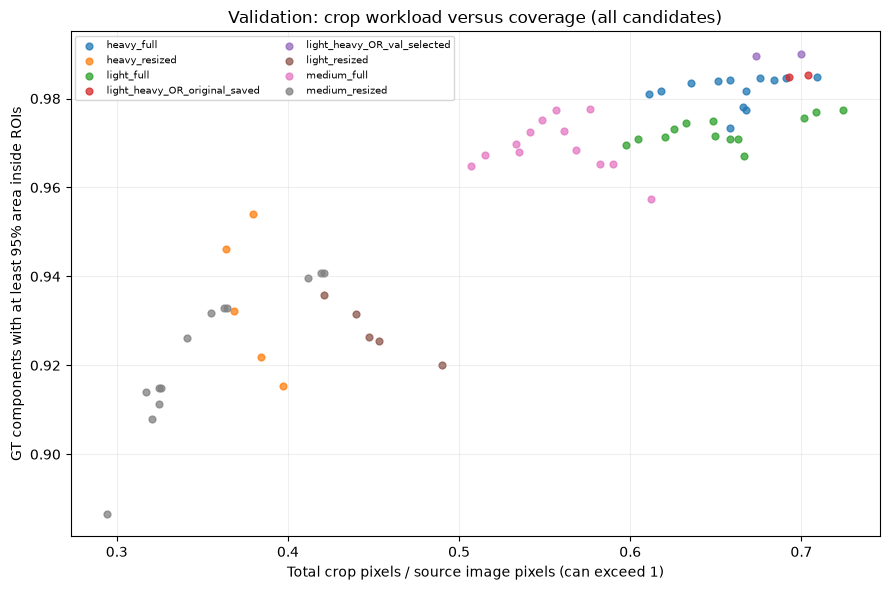

In [10]:
# Reference detector forward-only timing measured under original H5 common protocol.
h5 = pd.read_csv(original_root/'reports/H5_val_quality_cost_pareto.csv')
lat = h5[(h5['primary']==True)&(h5['policy']=='val_f1')].drop_duplicates('variant')
if not lat.comparable_protocol_verified.fillna(False).all():
    raise RuntimeError('Original latency benchmark protocols are not comparable. Do not optimize a combined cost.')
latencies=dict(zip(lat.variant,lat.latency_ms))
for col in ('candidate','threshold','context','min_area','roi_component_coverage_95','crops_per_pair'):
    assert col in all_val.columns
all_val=all_val.copy()
all_val['detector_forward_ms'] = all_val.apply(lambda r: (
    sum(latencies[x] for x in ('light_full','heavy_full')) if r.kind=='or'
    else latencies[r.candidate]),axis=1)
all_val['scenario_downstream_ms']=(all_val.crops_per_pair*HYPOTHETICAL_MS_PER_CROP +
    all_val.total_processed_fraction*(1024*1024/1e6)*HYPOTHETICAL_MS_PER_MPIX_CROPPED)
all_val['scenario_total_ms']=all_val.detector_forward_ms+all_val.scenario_downstream_ms
all_val['meets_coverage_95']=all_val.roi_component_coverage_95>=MIN_COVERAGE_95
all_val.to_csv(OUTPUT/'roi_validation_cost_scenarios.csv',index=False)

# Non-dominated points in (maximize GT component coverage, minimize crop workload, minimize detector cost).
def _pareto_flags(df):
    vals=df[['roi_component_coverage_95','total_processed_fraction','detector_forward_ms']].to_numpy(dtype=float)
    signed=vals * np.array([1,-1,-1])
    return [not np.any(np.all(signed>=signed[i],axis=1) & np.any(signed>signed[i],axis=1)) for i in range(len(df))]
all_val['pareto']=_pareto_flags(all_val)
pareto=all_val[all_val.pareto].sort_values('scenario_total_ms')
pareto.to_csv(OUTPUT/'roi_validation_pareto.csv',index=False)
print('Non-dominated configurations:',len(pareto),'of',len(all_val))
print('Feasible at target coverage:',int(all_val.meets_coverage_95.sum()),'of',len(all_val))

# One policy per candidate: MINIMUM scenario cost among feasible choices, otherwise
# MAXIMUM attained coverage followed by minimum cost. This is validation-only and
# cost-scenario dependent; preserve all Pareto alternatives in the separate report.
selected_rows=[]
for candidate,g in all_val.groupby('candidate',sort=True):
    feasible=g[g.meets_coverage_95]
    if len(feasible):
        chosen=feasible.sort_values(['scenario_total_ms','roi_component_coverage_95'],
            ascending=[True,False]).iloc[0]
    else:
        chosen=g.sort_values(['roi_component_coverage_95','scenario_total_ms'],
            ascending=[False,True]).iloc[0]
    selected_rows.append(chosen)
shortlist=pd.DataFrame(selected_rows).reset_index(drop=True)
shortlist.to_csv(OUTPUT/'roi_validation_frozen_choices.csv',index=False)
display(shortlist[['candidate','threshold','context','min_area','roi_component_coverage_95',
                   'forwarded_union_fraction','crops_per_pair','detector_forward_ms',
                   'scenario_total_ms','meets_coverage_95']].round(4))

# Plot actual observed ROI points, not fabricated lines.
fig,ax=plt.subplots(figsize=(9,6))
for candidate,gr in all_val.groupby('candidate'):
    ax.scatter(gr['total_processed_fraction'],gr['roi_component_coverage_95'],s=24,alpha=.75,label=candidate)
ax.set(xlabel='Total crop pixels / source image pixels (can exceed 1)',
       ylabel='GT components with at least 95% area inside ROIs',
       title='Validation: crop workload versus coverage (all candidates)')
ax.grid(alpha=.2);ax.legend(fontsize=7,ncol=2);fig.tight_layout()
fig.savefig(OUTPUT/'roi_coverage_vs_crop_workload.png',dpi=160);plt.show()

## 9. Medium all-seed validation (GPU, no training)

When `RUN_MEDIUM_SEEDS=True`, use original `Experiment` and existing project checkpoint-loading code. It runs saved seed checkpoints (42,123,777) for both BIT versions on validation. **No model retraining.** It may take longer than the CPU ROI sweep. The question is whether Medium's apparent geometric problem is robust across trained seeds. If these runs have previously been cached under the same immutable settings, they are reused.

In [11]:
medium_seed_summary=pd.DataFrame()
if RUN_MEDIUM_SEEDS:
    if not TRUST_OWN_SEED_CHECKPOINTS:
        raise RuntimeError('Explicitly enable TRUST_OWN_SEED_CHECKPOINTS only for your own checkpoint files.')
    seed_cfg=replace(settings,run_name='H08_medium_seeds_v2',
       variants=('medium_full','medium_resized'),include_other_seeds=True,
       trust_own_seed_checkpoints=True,cost_source='saved_benchmark',device=DEVICE)
    seed_experiment=Experiment(seed_cfg)
    for variant in seed_cfg.variants:
        seed_experiment.run_variant(variant,'val')
    # Evaluate only the existing project component/score metrics at each checkpoint's saved
    # validation threshold. Do not run the huge original H1-H5 freeze/bootstrapping pipeline.
    seed_rows=[]
    cutoffs=list(experiment.plan['size_cutoffs_px']) if experiment.plan else [100,1000]
    for s in seed_experiment.specs:
        image_metrics=[]
        for i in range(len(seed_experiment.datasets['val'])):
            gt=seed_experiment.gt('val',i)
            mask=seed_experiment.score(s,'val',i)>=np.float32(s['saved_threshold'])
            image_row,_=seed_experiment._evaluate_mask(mask,gt,cutoffs,geometry=False)
            image_metrics.append(image_row)
        sums=pd.DataFrame(image_metrics).select_dtypes(include='number').sum().to_dict()
        values=seed_experiment._counts_to_metrics(sums,len(image_metrics))
        seed_rows.append({'variant':s['variant'],'run_id':s['run_id'],'seed':s['seed'],
            'threshold':s['saved_threshold'],'pixel_f1':values['pixel_f1'],
            'pixel_recall':values['pixel_recall'],
            'object_recall_050':values['object_recall_050'],
            'gt_coverage_recall_050':values['gt_coverage_recall_050'],
            'completely_missed_fraction':values['completely_missed_fraction']})
    medium_seed_summary=pd.DataFrame(seed_rows)
    medium_seed_summary.to_csv(OUTPUT/'medium_all_seed_validation_metrics.csv',index=False)
    display(medium_seed_summary[['variant','seed','threshold','pixel_f1','pixel_recall',
            'object_recall_050','gt_coverage_recall_050','completely_missed_fraction']].round(4))
else:
    print('Seed GPU experiment skipped by explicit switch; no retraining conducted.')

Hashing validation/test inputs for cache integrity (no test metrics)...
NOTE: medium: Full and Resized have different architecture parameters. H1 is a pipeline comparison, not a pure resolution ablation.
NOTE: final_models_metrics.csv mixes validation/test fields. It is NOT used for evaluation or model ranking.
NOTE: Saved cost CSV and per-model benchmark JSON are separate measurements; do not mix their protocols. H5 defaults to one fresh common forward-only benchmark.
NOTE: Connected GT components are change regions, NOT guaranteed building-instance labels.
NOTE: Earlier test scores were already inspected: these analyses are exploratory/post-hoc.
NOTE: A deployment checkpoint is not an independent replicate of its source seed.
NOTE: No automatic hypothesis-proved labels are produced.
Output: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H08_medium_seeds_v2
Models/checkpoints: 6; primary pipelines: 2
Score cache upper estimate: 2.39 

,variant,seed,threshold,pixel_f1,pixel_recall,object_recall_050,gt_coverage_recall_050,completely_missed_fraction
0,medium_full,123,0.70,0.8609,0.8561,0.6463,0.8727,0.0857
1,medium_full,42,0.50,0.8602,0.8614,0.6460,0.8856,0.0739
2,medium_full,777,0.45,0.8488,0.8457,0.6291,0.8687,0.0832
3,medium_resized,123,0.70,0.7186,0.7639,0.0721,0.7812,0.1309
4,medium_resized,42,0.85,0.7120,0.7679,0.0660,0.7798,0.1370
5,medium_resized,777,0.65,0.7044,0.7401,0.0592,0.7704,0.1338


## 10. Medium seed × ROI consistency (validation)

Evaluate each Medium checkpoint using the **same ROI settings** selected from the primary seed. This distinguishes operating-point dependence from training-seed instability. Do not retune on test. The original primary models have already been evaluated in the main ROI sweep, but this section also evaluates the independently cached primary from the seed run for a consistent three-seed comparison.

In [12]:
medium_seed_roi=pd.DataFrame()
if RUN_MEDIUM_SEEDS:
    selected=[]
    for variant in ('medium_full','medium_resized'):
        c=shortlist[shortlist.candidate==variant].iloc[0]
        for s in seed_experiment.specs:
            if s['variant']!=variant: continue
            selected.append(dict(kind='single',candidate=f'{variant}_seed_{s["seed"]}',
                   run_id=s['run_id'],threshold=float(c.threshold),context=int(c.context),
                   min_area=int(c.min_area)))
    medium_seed_roi=_run_many(selected,split='val',ex=seed_experiment)
    medium_seed_roi.to_csv(OUTPUT/'medium_all_seed_roi_validation.csv',index=False)
    display(medium_seed_roi[['candidate','roi_component_coverage_95','roi_pixel_coverage',
                   'crops_per_pair','total_processed_fraction']].round(4))

[1/6] val: medium_full_seed_123 thr=0.35 margin=0 area=64
val  medium_full_seed_123                    : 16/64 elapsed 2.4s
val  medium_full_seed_123                    : 32/64 elapsed 4.3s
val  medium_full_seed_123                    : 48/64 elapsed 6.4s
val  medium_full_seed_123                    : 64/64 elapsed 8.4s
[2/6] val: medium_full_seed_42 thr=0.35 margin=0 area=64
val  medium_full_seed_42                     : 16/64 elapsed 2.4s
val  medium_full_seed_42                     : 32/64 elapsed 4.3s
val  medium_full_seed_42                     : 48/64 elapsed 6.4s
val  medium_full_seed_42                     : 64/64 elapsed 8.5s
[3/6] val: medium_full_seed_777 thr=0.35 margin=0 area=64
val  medium_full_seed_777                    : 16/64 elapsed 2.4s
val  medium_full_seed_777                    : 32/64 elapsed 4.3s
val  medium_full_seed_777                    : 48/64 elapsed 6.5s
val  medium_full_seed_777                    : 64/64 elapsed 8.5s
[4/6] val: medium_resized_seed_123 

,candidate,roi_component_coverage_95,roi_pixel_coverage,crops_per_pair,total_processed_fraction
0,medium_full_seed_123,0.9648,0.9826,31.7344,0.5067
1,medium_full_seed_42,0.9717,0.9881,34.8438,0.5518
2,medium_full_seed_777,0.9670,0.9814,35.0000,0.5551
3,medium_resized_seed_123,0.9078,0.9558,12.9219,0.3207
4,medium_resized_seed_42,0.9197,0.9588,11.6094,0.3177
5,medium_resized_seed_777,0.9060,0.9404,12.5625,0.3040


## 11. Medium retraining decision gate

We cannot logically distinguish bad *training* hyperparameters from inherent architecture limitations without a controlled retraining study. But we **can** decide whether a new HPO run is currently justified. Threshold/calibration and crop-geometry changes require no training. Inspect stability across three seeds and compare Medium's ROI quality to alternatives at similar crop workload. A Medium decision table is exported; interpret it as a diagnostic recommendation, not a causal proof.

In [13]:
medium_decisions=[]
for variant in ('medium_full','medium_resized'):
    best=shortlist[shortlist.candidate==variant].iloc[0]
    seeds=(medium_seed_roi[medium_seed_roi.candidate.str.startswith(variant+'_seed_')]
           if not medium_seed_roi.empty else pd.DataFrame())
    spread=(float(seeds.roi_component_coverage_95.max()-seeds.roi_component_coverage_95.min())
            if len(seeds)>=3 else float('nan'))
    # We deliberately do NOT invent a universal cutoff for "bad" seed instability.
    medium_decisions.append({'variant':variant,
         'primary_best_roi_component_coverage_95':float(best.roi_component_coverage_95),
         'primary_crop_workload':float(best.total_processed_fraction),
         'n_available_roi_seed_evaluations':len(seeds),'observed_roi_seed_range':spread,
         'threshold_dependence_evaluated':True,'crop_geometry_evaluated':True,
         'training_hyperparameter_causality_established':False,
         'next_action':('Compare against similarly priced single models; consider controlled HPO ONLY if ROI trade-off is still poor.'
                        if len(seeds)>=3 else 'Finish the seed validation analysis before deciding on HPO.')})
medium_decision=pd.DataFrame(medium_decisions)
medium_decision.to_csv(OUTPUT/'medium_retraining_decision_gate.csv',index=False)
display(medium_decision)

,variant,primary_best_roi_component_coverage_95,primary_crop_workload,n_available_roi_seed_evaluations,observed_roi_seed_range,threshold_dependence_evaluated,crop_geometry_evaluated,training_hyperparameter_causality_established,next_action
0,medium_full,0.964849,0.506700,3,0.006815,True,True,False,Compare against similarly priced single models...
1,medium_resized,0.907819,0.320672,3,0.013630,True,True,False,Compare against similarly priced single models...


## 12. Optional test — **only fixed validation-selected policies**

The final test has already been examined in H1–H5. Hence this notebook's test comparisons, even with frozen validation selection, are **exploratory**. Do not select new test thresholds or claim clean confirmatory p-values. First review Sections 5–11, then explicitly change `RUN_TEST_EVALUATION=True` and Run All (cached validation CSVs will be reused).

In [14]:
final_test=pd.DataFrame()
if RUN_TEST_EVALUATION:
    chosen=[]
    # One frozen validation policy for each of the six models; OR candidates if present.
    for _,r in shortlist.iterrows():
        if r.kind=='single':
            chosen.append(dict(kind='single',candidate=r.candidate,run_id=r.run_id,
                  threshold=float(r.threshold),context=int(r.context),min_area=int(r.min_area)))
        else:
            chosen.append(dict(kind='or',candidate=r.candidate,
                  model_a=r.model_a,model_b=r.model_b,
                  threshold_a=float(r.threshold_a),threshold_b=float(r.threshold_b),
                  threshold=0.5,context=int(r.context),min_area=int(r.min_area)))
    # This loop uses the SAME settings decided on validation; never tunes against test.
    final_test=_run_many(chosen,split='test')
    final_test.to_csv(OUTPUT/'roi_frozen_test_exploratory.csv',index=False)
    display(final_test[['candidate','roi_component_coverage_95','roi_pixel_coverage',
          'crops_per_pair','total_processed_fraction']].round(4))
else:
    print('TEST not accessed in this notebook. Enable only after inspecting frozen validation decisions.')

TEST not accessed in this notebook. Enable only after inspecting frozen validation decisions.


## 13. Paired bootstrap for the **frozen** test policies (exploratory)

In [15]:
ci_frame=pd.DataFrame()
if RUN_TEST_EVALUATION and len(final_test)>=2:
    records=[]
    baseline=final_test[final_test.candidate=='heavy_full']
    if baseline.empty:baseline=final_test.iloc[0:1]
    base_path=OUTPUT/'per_pair'/(baseline.iloc[0].config_id+'.csv')
    base=pd.read_csv(base_path).sort_values('pair_index').reset_index(drop=True)
    rng=np.random.default_rng(BOOTSTRAP_SEED)
    n=len(base)
    draws=rng.integers(0,n,size=(N_BOOTSTRAP,n))
    for _,candidate in final_test.iterrows():
        if candidate.config_id==baseline.iloc[0].config_id:continue
        x=pd.read_csv(OUTPUT/'per_pair'/(candidate.config_id+'.csv')).sort_values('pair_index').reset_index(drop=True)
        if not np.array_equal(base.sample_id.values,x.sample_id.values):raise RuntimeError('Pair mismatch for bootstrap')
        base_success=base.gt_components_covered_95.to_numpy();x_success=x.gt_components_covered_95.to_numpy()
        denominators=base.n_gt_components.to_numpy()
        # Components within one image are correlated: resample image pairs, not components.
        numer=(x_success-base_success)[draws].sum(axis=1)
        den=denominators[draws].sum(axis=1)
        if (den==0).any():raise RuntimeError('No GT components in one or more bootstrap replicates')
        boot=numer/den
        observed=(x_success-base_success).sum()/denominators.sum()
        lo,hi=np.percentile(boot,[2.5,97.5])
        records.append({'comparison':candidate.candidate+' - '+baseline.iloc[0].candidate,
           'observed_delta_component_coverage_95':observed,
           'paired_bootstrap_95_low':lo,'paired_bootstrap_95_high':hi,
           'resampling_unit':'image pair','status':'exploratory: test previously viewed'})
    ci_frame=pd.DataFrame(records)
    ci_frame.to_csv(OUTPUT/'roi_frozen_test_paired_bootstrap_exploratory.csv',index=False)
    display(ci_frame.round(4))
else:
    print('Paired test bootstrap deferred.')

Paired test bootstrap deferred.


## 14. Export shareable results ZIP

The export is intentionally compact: CSV/PNG/JSON only, no private imagery, raw probability maps, checkpoints, or source code. It contains test reports only if the test gate was enabled. Send the output archive for interpretation and for planning targeted Medium HPO (if needed) and Research II.

In [16]:
summary_manifest={
   'run':OUT_NAME,'created_utc':datetime.now(timezone.utc).isoformat(),
   'source_v1_signature':experiment.signature,
   'original_core_sha256':core_digest,
   'roi_project_source':str(roi_impl.__file__),
   'roi_project_sha256':hashlib.sha256(Path(roi_impl.__file__).read_bytes()).hexdigest(),
   'roi_validation_executed':RUN_ROI_VALIDATION,
   'medium_seed_inference_executed':RUN_MEDIUM_SEEDS,
   'test_evaluated':RUN_TEST_EVALUATION,
   'test_inferences':'exploratory; earlier H1-H5 experiments examined test',
   'cost_scope':'original H5 common detector-forward timing + hypothetical WHAT crop cost; NOT end-to-end measurement',
   'hypothetical_ms_per_crop':HYPOTHETICAL_MS_PER_CROP,
   'hypothetical_ms_per_mpix_cropped':HYPOTHETICAL_MS_PER_MPIX_CROPPED,
   'min_coverage_95':MIN_COVERAGE_95,
   'roi_geometry_source':'satchange.semantic.roi.extract_rois; dummy RGB for geometry-only study',
}
(OUTPUT/'roi_manifest.json').write_text(json.dumps(summary_manifest,indent=2),encoding='utf-8')
export_path=OUTPUT/'H08_roi_model_selection_v2_results.zip'
with zipfile.ZipFile(export_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT.rglob('*')):
        if not p.is_file() or p==export_path or p.suffix.lower() not in ('.csv','.png','.json'):
            continue
        z.write(p,arcname=p.relative_to(OUTPUT).as_posix())
print('DONE:',export_path,'size MB:',round(export_path.stat().st_size/1048576,2))
display(FileLink(str(export_path)))

DONE: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H08_roi_model_selection_v2/H08_roi_model_selection_v2_results.zip size MB: 0.25


/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H08_roi_model_selection_v2/H08_roi_model_selection_v2_results.zip